<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/27_QML_Privacy_Data_Leakage/VQNN_GradientInversion_Papadopoulos2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Gradient inversion of variational quantum neural networks: "A Numerical Gradient Inversion Attack in VQNNs" (Papadopoulos et al., 2025) step by step

This notebook re-implements, runs and checks the privacy attack of

> Georgios Papadopoulos, Shaltiel Eloul, Yash Satsangi, Jamie Heredge, Niraj Kumar, Chun-Fu Chen and Marco Pistoia (JPMorgan Chase, Global Technology Applied Research),
> "A Numerical Gradient Inversion Attack in Variational Quantum Neural-Networks",
> arXiv:2504.12806 [cs.LG], v2, 7 May 2025. DOI 10.48550/arXiv.2504.12806. https://arxiv.org/abs/2504.12806

The paper publishes no code. Everything below is written from the paper's description; the points where the paper is silent are listed in the table "What follows the paper and what had to be chosen".

**The story in five sentences.** In *federated learning* many clients train a shared model on their own private data and send only the **gradients** of the model to a server. For ordinary neural networks it is known that these gradients can be *inverted*: an
attacker searches for an input whose gradient matches the shared one and thereby recovers the private data. Earlier work argued that **variational quantum neural networks (VQNNs)** resist this attack, because the gradient of a quantum circuit is a trigonometric
polynomial whose "gradient-matching" loss has a huge number of local minima. The paper shows that this protection is weaker than claimed: estimate the gradient of the matching loss with *finite differences*, smooth away the fast oscillations with an *adaptive moving-average (low-pass) filter*,
and optionally stabilise the iteration with a *Kalman filter*; then the private input can be recovered with a mean-squared error below 0.005 (and down to about 1e-10 with more iterations) for small circuits, even for batches of two or three samples.
Finally, the paper adds Gaussian noise to the shared gradients (a differential-privacy style defence) and compares privacy against accuracy for a VQNN and a classical network.

**What the notebook does.**
1. Builds an *exact* state-vector simulator of the four VQNN architectures (RX or ZZ feature map + RY/RZ/CNOT ansatz), and proves with Qiskit that it implements the drawn circuits, their expectation values and their **parameter-shift gradients** to machine precision.
2. Downloads / generates the three data sources of the paper (cosine regression data, MNIST, Credit-Card Fraud), explores them and draws the real circuits.
3. Trains the VQNNs (Table I) and baselines.
4. Implements Algorithm 2 (finite differences + adaptive low-pass window + Kalman filter) and attacks the shared gradients (Table II, batches of 1, 2 and 3 samples, Figs. 4, 5/7, 8, 9, 15, 16, 17 analogues).
5. Checks the paper's central premise by repeating the attack **without** the low-pass filter.
6. Runs the Gaussian-noise study against a classical network attacked with Deep Leakage from Gradients (Table III, Figs. 10 and 11) and prints the paper's numbers next to ours with a verdict for every claim.

**How to run it.** Click the Colab badge, choose a CPU runtime and use *Runtime -> Run all*. The first cell installs pinned packages (if Colab asks to restart the session, restart and run all again). `FAST_MODE = True` is a class demo that finishes in 10-20 minutes on a CPU; `FAST_MODE = False` (the setting of the outputs stored in this notebook) uses the paper's trial counts and 5-fold cross-validation and took about 45 minutes on an 8-core CPU shared with other jobs (see the comment at the top of the configuration cell).
No GPU, quantum hardware, IBM token or Hugging Face token is needed: the three data sources are public. A Hugging Face token (Colab *Secrets* -> `HF_TOKEN`, or the environment variable `HF_TOKEN`) is only read, never printed, and is only needed if you replace a dataset by a gated one.

**What you get at the end:** the attack reproduced as a runnable algorithm, a table of the paper's claims next to this notebook's measurements, and an honest discussion of what the evidence does and does not show.

## The paper in one page

**Problem.** Gradient sharing in federated learning leaks the training data (gradient inversion attacks, e.g. Deep Leakage from Gradients). Is a *quantum* model safer? Prior theory ("over-parameterised" quantum models with highly expressive encodings) suggested yes.

**The model under attack (VQNN, Section III).** A classical input $x\in\mathbb R^J$ is encoded into $J$ qubits by a feature map $|\Phi(x)\rangle$ (here an $RX(x_j)$ rotation per qubit, or Qiskit's ZZFeatureMap). A trainable ansatz $V(\theta)$ (rotations about Y and Z plus CNOTs, or EfficientSU2) follows,
and the prediction is the expectation value $\hat y=\langle\Phi(x)|V(\theta)^\dagger\hat O V(\theta)|\Phi(x)\rangle$ of a Pauli-Z type observable. Training uses the MSE loss; gradients with respect to the $M$ trainable parameters are obtained with the **parameter-shift rule**
$g_m=\tfrac12[\hat y(\theta+\tfrac\pi2 e_m)-\hat y(\theta-\tfrac\pi2 e_m)]$ (Eq. 6).

**The attack (Section IV, Algorithm 2).** The attacker sees the shared gradient $g$ (not $x$, not $y$) and knows the model. It looks for $x'$ minimising $L(x')=\frac1M\sum_m(g'_m(x')-g_m)^2$ (Eq. 7). Because $g'$ is only available through circuit evaluations, $\partial L/\partial x'_j$ is estimated by central finite differences with steps $n h$, $n=1..N$ (Eq. 8), **averaged over $n$**
(a moving-average low-pass filter that removes the fast oscillations of the landscape, Eq. 9). A gradient-descent step follows (Eq. 10). The window $N$ is halved whenever the average cost stops falling fast enough (adaptive filter). Optionally a Kalman filter (Eq. 11-13, all-ones matrices, zero initial state) smooths the iterates.
An attack *succeeds* if $\mathrm{MSE}(x',x)\le 0.005$ after at most 200-250 iterations; the unit-vector (all ones) weights are used and no labels are needed.

**Data and models (Section V, Table I).** (i) generated cosine data $y=0.7\cos(x)$ (regression, $R^2$), (ii) MNIST (binary, balanced accuracy), (iii) Kaggle Credit-Card Fraud (binary, balanced accuracy). Models: *Simple*, *Simple Entangled*, *Complex* (Fig. 6) with 2 or 6 qubits and the *ZZEfficient* model (ZZFeatureMap + EfficientSU2). Table I lists 5-fold cross-validated train/test scores (80 %-99 %).

**Claims that can be checked here.**
* Table I: train/test performance of 12 VQNNs.
* Table II: one-shot success rates and MSE of the adaptive and Kalman attacks (10 attacks each) for 2- and 6-dimensional inputs and batches of 2 and 3 samples.
* Figs. 8 and 9: deeper ansätze need more attack iterations; a Kalman filter allows small windows (N = 16) where the plain adaptive attack fails.
* Appendix Figs. 15-17: longer runs reach MSE ~1e-10; random initial weights and trained models can also be attacked.
* Table III, Figs. 10 and 11: Gaussian noise on the shared gradients lowers the VQNN's accuracy and raises the inversion error; the classical network is attacked easily by DLG, the VQNN only by the new algorithm.
* The premise that finite differences alone (without the filter) fail on the VQNN landscape (Fig. 4, Fig. 5).

**Not checkable without the authors' code:** the exact circuits of Fig. 6 (only drawings), the hyper-parameters of Algorithm 2, the exact data preprocessing (how MNIST and Fraud are reduced to 2 or 6 inputs) and the neural-network sizes except for "16 weights".

## What follows the paper and what had to be chosen

Every item marked **CHOICE** below is also marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Circuit architectures | Fig. 6 shows *Simple*, *Simple Entangled*, *Complex* and ZZEfficient as drawings only (not recoverable from the text) | **CHOICE** (Qiskit objects, drawn in the circuit section): *Simple* = RX encoding + one RZ,RY layer; *Simple Entangled* = RX encoding + 3 x (RZ,RY + CNOT chain); *Complex* = RX encoding + EfficientSU2 (reps 3, linear CNOTs); *ZZEfficient* = ZZFeatureMap (reps 1, linear) + EfficientSU2 (reps 3, full); the batch attacks use a 6-layer *Simple Entangled* model (more equations than unknowns, as the paper demands) |
| Observable | "Pauli-Z" | **CHOICE**: the mean of $Z_j$ over all qubits, so $\hat y\in[-1,1]$ |
| What is shared | gradient of the MSE loss, Eq. 1 and 6; the attacker has neither $x$ nor $y$ | the parameter-shift gradient of the model output $\partial\hat y/\partial\theta$ (Eq. 6, as written; the label-dependent factor $2(\hat y-y)$ of the loss gradient is not modelled - see exercise 5) |
| Weights of the attacked model | all-ones vector (untrained); trained weights in Fig. 17 | same |
| Cosine data | $y=0.7\cos(x)$, 2 and 6 inputs | **CHOICE**: $x_j\sim U(0,2\pi)$, $y=0.7\cdot\frac1J\sum_j\cos x_j+\mathcal N(0,0.05^2)$ (noise so that $R^2<1$ as in Table I) |
| MNIST | binary task, reduced to 2 / 6 inputs (not specified) | **CHOICE**: digits 3 vs 5, PCA to $J$ components (fitted on the training split), MinMax to $[0,2\pi]$ |
| Fraud | Kaggle credit-card fraud, balanced accuracy | all 30 columns -> standardise -> the $J$ best F-test features (training split only) -> MinMax; class-balanced sample (120 / 300 per class). Angle range **CHOICE**: $[0,2\pi]$ for RX models, $[0,1]$ for the ZZ models (phases of the ZZFeatureMap are quadratic in $x$; on $[0,2\pi]$ the attack loop did not converge in our tuning runs) |
| Training | SGD or L-BFGS, 5-fold CV, 80 / 20 splits, MSE loss | **CHOICE**: Adam, lr 0.05, full batch, 60 (FAST) or 150 epochs; 2 (FAST) or 5 folds; initial $\theta\sim U(-\pi,\pi)$ |
| Attack hyper-parameters | $N\in\{16,32,64\}$, $K\le250$; $h$, lr and the stall threshold not given | **CHOICE**: $N_0=64$, $K=200$ (100 for the dense 6-qubit ZZ model in FAST mode), threshold 0.99, $h$ and lr tuned once on separate tuning targets (seed 777) |
| Step sizes of the finite differences | Eq. 8 uses $nh$ and divides by $2nh$; Algorithm 2 line 8 uses $(n+1)h$ | Eq. 8 as written (steps $nh$, $n=1..N$) |
| Update order | coordinate by coordinate inside one sweep (Algorithm 2) | same (Gauss-Seidel) |
| Kalman filter | $F,Q,P,H,R$ "all-ones elements", zero initial state | **CHOICE**: one scalar filter per coordinate with $F=H=Q=R=P_0=1$ and state 0 (a $J\times J$ matrix of ones would mix coordinates); an ablation shows what the filter really does |
| Success measure | $\mathrm{MSE}(x',x)\le0.005$, mean MSE $\pm$ SE of 10 attacks | same threshold. The RX-encoded model cannot distinguish $x$ from $x+2\pi$, so differences are reduced to $(-\pi,\pi]$ (**CHOICE**); the raw MSE is stored as well. For batches the summed gradient cannot reveal the *order* of the samples, so the MSE is minimised over permutations of the recovered samples. The MSE of Table II is the mean over the *successful* attacks (the paper's means are far below 0.005 although failures exist, so they can only be averages over successes) |
| Trials per row of Table II | 10 | 10 (4 for the slow 6-qubit ZZ row in FAST mode) |
| Noise study | Gaussian noise $\sigma$ on the shared gradient; model accuracy falls with $\sigma$ | noise is added during training (to the loss gradient) *and* to the gradient that the attacker sees; same $\sigma$ lists as Figs. 10 and 11 |
| Classical networks | "NN16x2" (cosine) and a 6-input network with 16 weights | $\tanh$ MLPs [2,16,16,1] and [6,2,1] (16 weights without the output bias is not possible, we count 17) |
| DLG | Zhu et al. 2019 | L-BFGS on $\lVert g'(x')-g\rVert^2$, 10 iterations, best of 5 random restarts |
| Simulator | Qiskit + PennyLane + PyTorch | an exact state-vector simulator in NumPy / PyTorch, **asserted equal** to Qiskit's `Statevector` for circuits, expectation values and parameter-shift gradients |
| Hardware | none | none |

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib, PyTorch,
# Pillow and huggingface_hub. Only Qiskit (circuit drawing and the equivalence checks) has to be added.
# The pip line runs on Colab (or wherever Qiskit is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("qiskit") is None:
    %pip install -q "qiskit==2.5.2" pylatexenc
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("Qiskit already present; skipping pip install.")

Qiskit already present; skipping pip install.


In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
FAST_MODE   = False            # True: class demo (10-20 minutes on a shared 8-core CPU). False: the paper's trial counts and 5-fold CV (about 45 minutes, measured on the same machine).
SEED        = 42              # CHOICE: the paper gives no seed
DATA_DIR    = "data"          # cache for the downloaded files (relative to the working directory)
IBM_TOKEN   = ""              # not used: the paper simulates everything; there is no hardware cell in this notebook
TORCH_THREADS = 4             # CPU threads for PyTorch / NumPy

# ---- data ----
MNIST_PAIR  = (3, 5)          # CHOICE: the paper only says "MNIST, binary classification"; 3-vs-5 is a classically hard pair
COS_NOISE   = 0.05            # CHOICE: Gaussian label noise on y = 0.7 * mean_j cos(x_j), so that R^2 < 1 as in the paper's Table I
ZZ_REPS, ZZ_ENT = 1, "linear"   # CHOICE: ZZFeatureMap repetitions and CNOT pattern (paper: only "ZZFeatureMap"). reps=2/full made the 6-qubit landscape unattackable in our tuning runs
ANGLE_HI    = {"rx": 2 * 3.141592653589793,   # data angles live in [0, 2 pi] for RX encoding (paper Fig. 2 and 4: x in [0, 2 pi])
               "zz": 1.0}                    # CHOICE: [0, 1] behind the ZZFeatureMap (its phases are quadratic in x; on [0, 2 pi] the
                                             #         gradient landscape is far too rugged for the attack loop, see the exploration section)
# ---- Table I: training of the VQNNs (paper: 5-fold cross-validation, 80/20 splits) ----
TRAIN_LR    = 0.05            # CHOICE: Adam learning rate (paper: SGD or L-BFGS, no value given)
if FAST_MODE:
    N_COS, N_PER_CLASS = 300, 120         # samples per cosine set / per class for MNIST and Fraud
    CV_FOLDS, EPOCHS   = 2, 60            # paper: 5 folds
    N_TRIALS_2D, N_TRIALS_6D, N_TRIALS_BATCH, N_TRIALS_ZZ6 = 10, 10, 10, 4   # attacks per row of Table II (paper: 10); the dense 6-qubit ZZ model is the slow one
    K_ATTACK  = {2: 200, 6: 200}          # attack iterations for 2- and 6-dimensional inputs (paper: <= 250)
    K_ZZ6     = 100                       # the dense 6-qubit ZZ model needs ~30x more time per iteration: shorter budget in FAST mode
    N_DP_ATTACKS, N_DP_ATTACKS_FRAUD, DP_EPOCHS, NN_EPOCHS = 3, 2, 60, 300   # attacks per noise level (cosine / fraud), training epochs of the VQNN / of the classical NN
    DP_SIG_COS, DP_SIG_FRAUD = [0.0, 0.05, 0.08], [0.0, 0.10]                  # noise levels (paper: 0, 0.02, 0.05, 0.07, 0.08 and 0, 0.05, 0.10, 0.14)
    N_FIG17 = 2                           # attacks on the trained 6-qubit ZZ model (slow)
    N_FIG8, N_FIG9, FIG9_K = 6, 6, 200    # trials per curve in Fig. 8 / Fig. 9 analogues
else:
    N_COS, N_PER_CLASS = 600, 300
    CV_FOLDS, EPOCHS   = 5, 150
    N_TRIALS_2D, N_TRIALS_6D, N_TRIALS_BATCH, N_TRIALS_ZZ6 = 10, 10, 10, 10
    K_ATTACK  = {2: 200, 6: 200}
    K_ZZ6     = 200
    N_DP_ATTACKS, N_DP_ATTACKS_FRAUD, DP_EPOCHS, NN_EPOCHS = 5, 3, 150, 600
    DP_SIG_COS, DP_SIG_FRAUD = [0.0, 0.02, 0.05, 0.07, 0.08], [0.0, 0.05, 0.10, 0.14]
    N_FIG17 = 4
    N_FIG8, N_FIG9, FIG9_K = 10, 10, 250

# ---- attack hyper-parameters (Algorithm 2). The paper does not give them: CHOICE, tuned once on separate tuning targets
#      (random seed 777, disjoint from the evaluation seeds) over lr in {0.3 ... 3000}, h in {0.005 ... 0.2}, threshold in {0.9 ... 1.02}.
#      lr has to shrink with the gradient scale of the model (the observable is the mean over qubits, so gradients scale like 1/J).
ATK_N0, ATK_THR = 64, 0.99            # initial moving-average window N and the "stalled" ratio test of Algorithm 2 (line 25)
ATK_LR = {("rx", 2): 10.0, ("rx", 6): 300.0, ("zz", 2): 1.0, ("zz", 6): 20.0}     # gradient-descent learning rate (Eq. 10)
ATK_H  = {"rx": 0.02, "zz": 0.02}      # finite-difference step h (Eq. 8)
SUCCESS_MSE = 0.005                   # paper: an attack succeeds when MSE(x', x) <= 0.005

In [3]:
import os, io, time, json, math, warnings, importlib.metadata as md
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore")
import torch
import qiskit
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import KFold, StratifiedKFold
from sklearn.metrics import r2_score, balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

# Hugging Face token: only needed for GATED datasets. The three datasets used here are public, so an empty token is fine.
# If you adapt the notebook to a gated dataset, store your own token in Colab (Secrets > HF_TOKEN) or in the HF_TOKEN
# environment variable; it is never printed or written anywhere by this notebook.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

matplotlib.rcParams["figure.dpi"] = 80                      # keeps the saved figures small
torch.set_default_dtype(torch.float64)
torch.set_num_threads(TORCH_THREADS)
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
TWO_PI = 2 * np.pi

import sklearn
print("qiskit", qiskit.__version__, "| torch", torch.__version__, "| numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)
print("FAST_MODE =", FAST_MODE, "| CV folds =", CV_FOLDS, "| epochs =", EPOCHS, "| attack trials 2D/6D =", N_TRIALS_2D, N_TRIALS_6D)

qiskit 2.5.2 | torch 2.14.1+cpu | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1
FAST_MODE = False | CV folds = 5 | epochs = 150 | attack trials 2D/6D = 10 10


## 1. An exact simulator for the VQNNs (and why it can be trusted)

A VQNN with $J$ qubits has a $2^J$-dimensional state ($J\le6$ here), so it can be simulated *exactly* with matrices; no sampling noise is involved, which is also how the paper treats the gradients ("expectation values").
The next three cells implement the model

$$\hat y(x;\theta)=\langle\Phi(x)|\,V(\theta)^\dagger\,\hat O\,V(\theta)\,|\Phi(x)\rangle,\qquad \hat O=\tfrac1J\sum_j Z_j ,$$

* **Feature maps** $|\Phi(x)\rangle$ in closed form: one $RX(x_j)$ per qubit, or Qiskit's `ZZFeatureMap` (Hadamards and diagonal phases).
* **Ansatz** $V(\theta)$ as a *Qiskit circuit* (so that the drawing in the circuit section is the object that runs); the simulator reads its gate list and multiplies the corresponding unitaries (neighbouring single-qubit gates are merged into one Kronecker product for speed).
* **The shared gradient.** The parameter-shift rule says $g_m=\tfrac12[\hat y(\theta+\tfrac\pi2e_m)-\hat y(\theta-\tfrac\pi2e_m)]$. Both terms are expectation values of *fixed* matrices, so $g_m(x)=\langle\Phi(x)|D_m|\Phi(x)\rangle$ with $D_m=\tfrac12(V_{+m}^\dagger\hat OV_{+m}-V_{-m}^\dagger\hat OV_{-m})$ pre-computed once for the attacked weights.
  For the RX encoding the state of every qubit is $(I+\cos x_j\,Z+\sin x_j\,(-Y))/2$, hence $g_m(x)=\sum_\sigma C_{m\sigma}\prod_jf_{\sigma_j}(x_j)$ with $f=(1,\cos,\sin)$: **the gradient is a trigonometric polynomial of degree one in every input**. This is exactly the "multivariate Chebyshev / Fourier" structure
  that makes the gradient-matching loss so oscillatory, and it allows an equally exact but 10-100x cheaper evaluation inside the attack loop. A cell below asserts that all three evaluation routes agree to ~1e-15 with Qiskit's own `Statevector`.

In [4]:
import numpy as np, torch
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import zz_feature_map, efficient_su2

# ---------- exact state-vector simulator (little-endian: qubit 0 is the least significant bit) ----------
_PERM = {}
def cx_perm(c, t, n):
    """Index map of CNOT(control c, target t) on the 2^n basis states."""
    key = (c, t, n)
    if key not in _PERM:
        k = np.arange(2 ** n)
        _PERM[key] = torch.as_tensor(np.where((k >> c) & 1 == 1, k ^ (1 << t), k))
    return _PERM[key]

def gates_all(kinds, theta):
    """All single-qubit rotation matrices at once. kinds[m] in {"rx","ry","rz"}; returns an (M, 2, 2) complex tensor
    (differentiable in theta).  RX(a) = exp(-i a X/2), RY(a) = exp(-i a Y/2), RZ(a) = exp(-i a Z/2)."""
    c, s = torch.cos(theta / 2), torch.sin(theta / 2)
    z = torch.zeros_like(c)
    k = torch.as_tensor([{"rx": 0, "ry": 1, "rz": 2}[x] for x in kinds])
    def pick(rx, ry, rz):
        return torch.where(k == 0, rx, torch.where(k == 1, ry, rz))
    a = torch.complex(pick(c, c, c), pick(z, z, -s))              # matrix element [0, 0]
    b = torch.complex(pick(z, -s, z), pick(-s, z, z))             # [0, 1]
    cc = torch.complex(pick(z, s, z), pick(-s, z, z))             # [1, 0]
    d = torch.complex(pick(c, c, c), pick(z, z, s))               # [1, 1]
    return torch.stack([a, b, cc, d], dim=1).reshape(-1, 2, 2)

def z_diag(n):
    """Diagonal of the observable O = (1/n) * sum_j Z_j  (CHOICE: the paper only says 'Pauli-Z')."""
    k = np.arange(2 ** n)
    return sum(1.0 - 2.0 * ((k >> j) & 1) for j in range(n)) / n

# ---------- feature maps |Phi(x)> (closed form, batched over data points) ----------
def fm_rx(X):
    """Angle encoding: one RX(x_j) on qubit j. Returns (B, 2^n) complex states."""
    B, n = X.shape
    psi = np.ones((B, 1), dtype=complex)
    for q in range(n):
        a = np.stack([np.cos(X[:, q] / 2), -1j * np.sin(X[:, q] / 2)], axis=1)
        psi = (a[:, :, None] * psi[:, None, :]).reshape(B, -1)
    return psi

def _hadamard_all(n):
    H = np.array([[1, 1], [1, -1]]) / np.sqrt(2)
    M = np.ones((1, 1))
    for _ in range(n):
        M = np.kron(H, M)
    return M

def fm_zz(X, reps=2, ent="full"):
    """Qiskit ZZFeatureMap (entanglement='full'). One repetition is H^n followed by a diagonal phase
    exp(i * (sum_j 2 x_j b_j + sum_{i<j} 2 (pi - x_i)(pi - x_j) (b_i xor b_j))), b = computational-basis bits."""
    B, n = X.shape
    d = 2 ** n
    k = np.arange(d)
    bits = np.stack([(k >> j) & 1 for j in range(n)], axis=0).astype(float)      # (n, d)
    Hn = _hadamard_all(n)
    psi = np.full((B, d), 1.0 / np.sqrt(d), dtype=complex)                      # H^n |0...0>
    phase = 2.0 * X @ bits                                                       # (B, d)
    pairs = [(i, j) for i in range(n) for j in range(i + 1, n)] if ent == "full" else [(i, i + 1) for i in range(n - 1)]
    for i, j in pairs:
        if True:
            par = np.abs(bits[i] - bits[j])
            phase = phase + 2.0 * ((np.pi - X[:, i]) * (np.pi - X[:, j]))[:, None] * par[None, :]
    for r in range(reps):
        if r > 0:
            psi = psi @ Hn.T
        psi = psi * np.exp(1j * phase)
    return psi

In [5]:
# ---------- trainable ansatz V(theta) as a Qiskit circuit, and its gate list ----------
def ansatz_circuit(kind, n, layers=3):
    """Qiskit circuit of the trainable part V(theta); parameters are ordered theta[0..M-1].
    simple      : one layer RZ, RY on every qubit, no entanglement
    simple_ent  : `layers` x (RZ, RY on every qubit + CNOT chain)
    complex     : Qiskit EfficientSU2 (RY, RZ + CNOT chain 'linear'), `layers` repetitions + final rotation layer
    zzeff       : Qiskit EfficientSU2 with its 'full' CNOT pattern (used behind the ZZFeatureMap)"""
    if kind == "complex":
        return efficient_su2(n, reps=layers, entanglement="linear", parameter_prefix="theta")
    if kind == "zzeff":
        return efficient_su2(n, reps=layers, entanglement="full", parameter_prefix="theta")
    th = ParameterVector("theta", 0)
    qc = QuantumCircuit(n)
    L = 1 if kind == "simple" else layers
    idx = 0
    for l in range(L):
        for q in range(n):
            th.resize(idx + 2)
            qc.rz(th[idx], q); qc.ry(th[idx + 1], q); idx += 2
        if kind == "simple_ent":
            for q in range(n - 1):
                qc.cx(q, q + 1)
    return qc

def parse_ops(qc):
    """Gate list [(name, qubits, parameter index or None)] of a Qiskit circuit made of rx/ry/rz/cx."""
    pidx = {p: i for i, p in enumerate(qc.parameters)}
    ops = []
    for inst in qc.data:
        name = inst.operation.name
        qs = [qc.find_bit(q).index for q in inst.qubits]
        if name in ("rx", "ry", "rz"):
            ops.append((name, qs, pidx[inst.operation.params[0]]))
        elif name == "cx":
            ops.append(("cx", qs, None))
        elif name == "barrier":
            continue
        else:
            raise ValueError("unsupported gate " + name)
    return ops

def fourier_coeffs(D, n):
    """C[m, sigma] = 2^-n Tr(D_m  (x)_q P_{sigma_q}) with P = (I, Z, -Y). These are the exact coefficients of
    g_m(x) = Tr(D_m |Phi(x)><Phi(x)|) for |Phi(x)> = (x)_q RX(x_q)|0>, whose qubit-q density matrix is
    (I + cos(x_q) Z + sin(x_q) (-Y)) / 2.  Digit sigma_q is the q-th base-3 digit (qubit 0 = least significant)."""
    M = D.shape[0]
    P = np.array([np.eye(2), np.diag([1.0, -1.0]), -np.array([[0, -1j], [1j, 0]])])      # P[s][row, col]
    T = D.reshape((M,) + (2,) * n + (2,) * n)               # axes: m, a_{n-1}..a_0, b_{n-1}..b_0
    for q in range(n):
        r = n - q                                           # a-axes still present; first a is axis 1, first b is axis 1 + r
        T = np.tensordot(T, P, axes=([1, 1 + r], [2, 1]))   # sum_{a,b} T[a,b] P[b,a]; the sigma axis is appended last
    C = T.reshape(M, -1) / 2 ** n
    assert np.abs(C.imag).max() < 1e-10
    return np.ascontiguousarray(C.real)

In [6]:
class VQNN:
    """y_hat(x; theta) = <Phi(x)| V(theta)^dagger O V(theta) |Phi(x)>   (paper Eq. 3-5)."""
    def __init__(self, fm, ansatz, n, layers=3, zz_reps=2, zz_ent="full"):
        self.fm_name, self.ansatz_name, self.n, self.d = fm, ansatz, n, 2 ** n
        self.zz_reps, self.zz_ent = zz_reps, zz_ent
        self.qc_ans = ansatz_circuit(ansatz, n, layers)
        self.ops = parse_ops(self.qc_ans)
        self.M = self.qc_ans.num_parameters
        self.o = torch.as_tensor(z_diag(n))
        self.kinds = [None] * self.M
        for name, qs, pi in self.ops:
            if pi is not None:
                self.kinds[pi] = name
        self.C = None

    def phi(self, X):
        X = np.atleast_2d(np.asarray(X, dtype=float))
        return fm_rx(X) if self.fm_name == "rx" else fm_zz(X, self.zz_reps, self.zz_ent)

    def unitary(self, theta):
        """V(theta) as a d x d complex matrix (differentiable). Single-qubit gates between two CNOT layers are merged
        into one Kronecker product, so a 6-qubit ansatz costs only a handful of 64 x 64 matrix products."""
        theta = torch.as_tensor(theta, dtype=torch.float64)
        n, I2 = self.n, torch.eye(2, dtype=torch.complex128)
        V = torch.eye(self.d, dtype=torch.complex128)
        pend = [None] * n                                       # pending single-qubit product per qubit
        Gs = gates_all(self.kinds, theta)

        def flush(V):
            if all(p is None for p in pend):
                return V
            K = torch.ones((1, 1), dtype=torch.complex128)
            for q in range(n - 1, -1, -1):                       # little-endian: qubit n-1 is the leftmost factor
                K = torch.kron(K, pend[q] if pend[q] is not None else I2)
            for q in range(n):
                pend[q] = None
            return K @ V

        for name, qs, pi in self.ops:
            if name == "cx":
                V = flush(V)
                V = V[cx_perm(qs[0], qs[1], n), :]
            else:
                G = Gs[pi]
                pend[qs[0]] = G if pend[qs[0]] is None else G @ pend[qs[0]]
        return flush(V)

    def predict_t(self, Phi_t, theta):
        """Model output for torch complex states (differentiable in theta)."""
        V = self.unitary(theta)
        psi = Phi_t @ V.T
        return (psi.real ** 2 + psi.imag ** 2) @ self.o

    def predict(self, X, theta):
        with torch.no_grad():
            return self.predict_t(torch.as_tensor(self.phi(X)), theta).numpy()

    # --- exact parameter-shift gradient: g_m(x) = (y(theta + pi/2 e_m) - y(theta - pi/2 e_m)) / 2 = <Phi(x)| D_m |Phi(x)> ---
    def set_theta(self, theta):
        """Fix the weights (the attacked model) and pre-compute the 2M shifted observables D_m."""
        theta = np.asarray(theta, dtype=float).copy()
        self.theta = theta
        O = torch.diag(self.o).to(torch.complex128)
        D = []
        with torch.no_grad():
            for m in range(self.M):
                tp, tm = theta.copy(), theta.copy()
                tp[m] += np.pi / 2; tm[m] -= np.pi / 2
                Vp, Vm = self.unitary(tp), self.unitary(tm)
                D.append(0.5 * (Vp.conj().T @ O @ Vp - Vm.conj().T @ O @ Vm))
        D = torch.stack(D).numpy()                                        # (M, d, d), Hermitian
        self.Dfull = np.ascontiguousarray(D.reshape(self.M * self.d, self.d))   # (M*d, d): stacked D_m
        self.C = fourier_coeffs(D, self.n) if self.fm_name == "rx" else None
        self._Cj = {}

    def grad_dense(self, X):
        """Parameter-shift gradient for each row of X -> (B, M), by contracting the states with D_m."""
        P = self.phi(X)                                                   # (B, d)
        Y = (self.Dfull @ P.T).reshape(self.M, self.d, len(P))            # D_m |Phi_b>  for all m, b
        return np.einsum("ba,mab->bm", P.conj(), Y).real

    def grad(self, X):
        """Same gradient. For the RX encoding it is evaluated in its exact trigonometric (Fourier) form, which is about
        10x cheaper at 6 qubits: g_m(x) = sum_sigma C[m, sigma] * prod_q f_{sigma_q}(x_q) with f = (1, cos, sin)."""
        if self.C is None:
            return self.grad_dense(X)
        X = np.atleast_2d(np.asarray(X, dtype=float))
        F = np.ones((len(X), 1))
        for q in range(self.n - 1, -1, -1):                              # qubit 0 ends up as the least significant digit
            f = np.stack([np.ones(len(X)), np.cos(X[:, q]), np.sin(X[:, q])], axis=1)
            F = (F[:, :, None] * f[:, None, :]).reshape(len(X), -1)
        return F @ self.C.T

    def grad_line(self, x, j, vals):
        """Gradient at x with coordinate j replaced by each entry of vals -> (len(vals), M). For the RX encoding the other
        qubits' factors are shared by all evaluation points, so this is exact and very cheap (used by the attack loop)."""
        n = self.n
        if self.C is None:
            X = np.repeat(np.asarray(x, dtype=float)[None, :], len(vals), axis=0)
            X[:, j] = vals
            return self.grad_dense(X)
        if j not in self._Cj:
            self._Cj[j] = np.ascontiguousarray(
                np.moveaxis(self.C.reshape((self.M,) + (3,) * n), n - j, 1).reshape(self.M, 3, -1))
        F = np.ones(1)
        for q in range(n - 1, -1, -1):
            if q != j:
                F = np.outer(F, [1.0, np.cos(x[q]), np.sin(x[q])]).ravel()
        G = self._Cj[j] @ F                                               # (M, 3)
        vals = np.asarray(vals, dtype=float)
        fv = np.stack([np.ones(len(vals)), np.cos(vals), np.sin(vals)], axis=1)
        return fv @ G.T

    # --- the Qiskit circuit that corresponds to this model (for drawing and for the equivalence check) ---
    def qiskit_circuit(self):
        n = self.n
        qc = QuantumCircuit(n)
        if self.fm_name == "rx":
            x = ParameterVector("x", n)
            for q in range(n):
                qc.rx(x[q], q)
        else:
            qc.compose(zz_feature_map(n, reps=self.zz_reps, entanglement=self.zz_ent, parameter_prefix="x"), inplace=True)
        qc.barrier()
        qc.compose(self.qc_ans, inplace=True)
        return qc

    def bind(self, qc, x, theta):
        """Assign data angles x and weights theta to a circuit from qiskit_circuit()."""
        idx = lambda p: int(p.name.split("[")[1][:-1])
        vals = {}
        for p in qc.parameters:
            vals[p] = float(x[idx(p)]) if p.name.startswith("x") else float(theta[idx(p)])
        return qc.assign_parameters(vals)

def make_model(name, n, layers=3, zz_reps=ZZ_REPS, zz_ent=ZZ_ENT):
    """The four architectures of the notebook (Fig. 6 of the paper is not readable in the extracted text; see the table of choices)."""
    if name == "Simple":        return VQNN("rx", "simple", n)
    if name == "SimpleEnt":     return VQNN("rx", "simple_ent", n, layers=layers)
    if name == "Complex":       return VQNN("rx", "complex", n, layers=layers)
    if name == "ZZEfficient":   return VQNN("zz", "zzeff", n, layers=layers, zz_reps=zz_reps, zz_ent=zz_ent)
    raise ValueError(name)

## 2. The attack (Algorithm 2) in plain words

The attacker holds the shared gradient $g\in\mathbb R^M$ and the model. It wants $x$ with $g(x)=g$.

1. **Guess** a random $x'$. **Score** it with the *gradient loss* $L(x')=\frac1M\sum_m(g_m(x')-g_m)^2$. $L=0$ exactly at the secret (and at other inputs with the same gradient).
2. **Estimate the slope of $L$** along each input coordinate by *central finite differences* $[L(x'+nhe_j)-L(x'-nhe_j)]/(2nh)$ for window sizes $n=1,\dots,N$ and **average** the $N$ estimates. Large steps $nh$ blur the landscape: oscillations that are faster than $1/(Nh)$ cancel
   (this is the *moving-average low-pass filter*). The slope is therefore that of a *smoothed* loss, which has a broad valley leading towards the global minimum.
3. **Step downhill**, $x'_j\leftarrow x'_j-\mathrm{lr}\cdot\text{slope}$, one coordinate after the other.
4. **Shrink the window.** Close to the secret the smoothed valley is no longer needed (and blurs the answer), so $N$ is halved whenever the average loss of a sweep is not smaller than `thr` x the previous one ("adaptive" filter).
5. **Optional Kalman filter.** Each coordinate passes through a scalar Kalman filter with all-ones $F,H,Q,R,P_0$ and state 0. With these numbers the gain converges to 0.618 (the golden-ratio fixed point), so the filter effectively multiplies the step by ~0.62 and, in the very first
   step, pulls the random start by a factor 2/3 towards 0. The ablation further below separates these two effects.

The cell below implements exactly this (`invert`). The true secret is only used to *record* the error history, never to take a step. `run_trials` runs many attacks, optionally adds Gaussian noise to the shared gradient, and stores for each attack the final MSE, whether it succeeded ($\mathrm{MSE}\le0.005$), and the full path.

In [7]:
import itertools

def circ_mse(u, v, b=1):
    """MSE between angle vectors after reducing the difference to (-pi, pi]: the model cannot tell x from x + 2 pi
    (RX encoding), and the attacker knows the data lie in [0, 2 pi), so a result that is off by 2 pi is projected back."""
    if b > 1:                                               # a summed batch gradient cannot reveal the ORDER of the samples
        U, V = u.reshape(b, -1), v.reshape(b, -1)
        return min(circ_mse(U[list(p)].ravel(), V.ravel()) for p in itertools.permutations(range(b)))
    d = (u - v + np.pi) % (2 * np.pi) - np.pi
    return (d ** 2).mean()

def line_grads(model, u, b, J, c, deltas):
    """Summed gradient of a batch of b inputs for the points u + delta * e_c (c indexes the flattened batch) -> (len(deltas), M)."""
    s, j = divmod(c, J)
    X = u.reshape(b, J)
    g = model.grad_line(X[s], j, X[s, j] + deltas)
    if b > 1:                                               # gradients of a batch are summed before they are shared
        g = g + sum(model.grad(X[t])[0] for t in range(b) if t != s)[None, :]
    return g

def grad_sum(model, u, b, J):
    return model.grad(u.reshape(b, J)).sum(0)

def invert(model, g_target, x_true, x0, K=200, N0=64, h=0.02, lr=10.0, thr=0.99,
           kalman=False, kalman_init="zero", Q=1.0, R=1.0, stop_mse=None):
    """Algorithm 2 of the paper. Cost L(x') = mean_m (g'_m(x') - g_m)^2 (Eq. 7). For every coordinate c:
    central differences with steps n*h, n = 1..N (Eq. 8), their average (moving-average low-pass filter, Eq. 9),
    a gradient-descent step (Eq. 10) and optionally a scalar Kalman filter per coordinate (Eq. 11-13).
    N is halved whenever the average cost of the last sweep did not drop below `thr` times the previous one.
    x_true and x0 have shape (b, J); only x_true is used for the bookkeeping (MSE history), never for the update."""
    b, J = x0.shape
    u = x0.astype(float).ravel().copy()
    D = u.size
    N = N0
    s = np.zeros(D) if kalman_init == "zero" else u.copy()      # Kalman state estimate (paper: zero initial state)
    Pk = np.ones(D)                                             # Kalman covariance (paper: all-ones F, H, Q, P, R)
    ns = np.arange(1, N0 + 1)
    hist = {"mse": [], "raw": [], "gloss": [], "N": []}
    Lbar_prev, u_true = None, x_true.ravel()
    for k in range(K):
        Lsum, Lcnt = 0.0, 0
        for c in range(D):
            nn = ns[:N]
            g = line_grads(model, u, b, J, c, np.concatenate([nn * h, -nn * h]))
            loss = ((g - g_target[None, :]) ** 2).mean(1)
            dn = (loss[:N] - loss[N:]) / (2 * nn * h)             # Eq. 8
            dL = dn.mean()                                        # Eq. 9
            Lsum += loss.sum(); Lcnt += 2 * N
            z = u[c] - lr * dL                                    # Eq. 10
            if kalman:                                            # Eq. 11-13 with scalar F = H = Q = R = 1 per coordinate
                Ph = Pk[c] + Q
                Dk = Ph / (Ph + R)
                s[c] = s[c] + Dk * (z - s[c])
                Pk[c] = (1 - Dk) * Ph
                u[c] = s[c]
            else:
                u[c] = z
        Lbar = Lsum / Lcnt
        if Lbar_prev is not None and Lbar / Lbar_prev > thr:
            N = max(1, N // 2)
        Lbar_prev = Lbar
        gl = ((grad_sum(model, u, b, J) - g_target) ** 2).mean()
        hist["mse"].append(float(circ_mse(u, u_true, b))); hist["raw"].append(float(((u - u_true) ** 2).mean()))
        hist["gloss"].append(float(gl)); hist["N"].append(N)
        if stop_mse is not None and hist["mse"][-1] <= stop_mse:
            break
    return u.reshape(b, J), hist

def run_trials(model, targets, atk, kalman, K, g_noise=0.0, noise_seed=0, **kw):
    """Run the attack on a list of (x_true, x0) pairs; returns a list of result dicts (one per trial).
    g_noise > 0 adds N(0, g_noise^2) to every component of the shared gradient (the paper's Gaussian defence)."""
    res, nrng = [], np.random.default_rng(noise_seed)
    for x, x0 in targets:
        b, J = x.shape
        g = grad_sum(model, x.ravel(), b, J) + g_noise * nrng.standard_normal(model.M)     # optional Gaussian noise on the shared gradient
        xr, h = invert(model, g, x, x0, K=K, N0=atk.get("N0", ATK_N0), h=atk["h"], lr=atk["lr"], thr=atk.get("thr", ATK_THR),
                       kalman=kalman, **kw)
        hit = next((i + 1 for i, v in enumerate(h["mse"]) if v <= SUCCESS_MSE), None)
        res.append(dict(mse=h["mse"][-1], raw_mse=h["raw"][-1], success=h["mse"][-1] <= SUCCESS_MSE, first_hit=hit, gloss=h["gloss"][-1], hist=h))
    return res

## 3. Data: cosine, MNIST and Credit-Card Fraud

Three sources are used, exactly as in the paper's Section V:

* **Cosine regression data.** Generated: inputs $x_j\sim U(0,2\pi)$ and a target built from $0.7\cos(x)$ (see the table of choices for the $J$-input version). This is the paper's own synthetic data set, so "generating" it is not a substitution.
* **MNIST** (real handwritten digits, public Hugging Face mirror `ylecun/mnist`, OpenML as fallback): a binary task between two digits.
* **Credit-Card Fraud** (real European card transactions, Kaggle `mlg-ulb`, public Hugging Face mirror `David-Egea/Creditcard-fraud-detection`, 284,807 rows of which 492 frauds). The 150 MB CSV is downloaded once, reduced to all frauds + 5,000 legitimate rows (about 1.6 MB), and the large file is deleted.

Every transform (PCA, standardisation, feature selection, MinMax scaling) is **fitted on the training split only** and test angles are clipped to the training range. One feature per qubit; the data enter the circuit as rotation angles.

In [8]:
# ---- three data sources of the paper: generated cosine data, MNIST (binary task) and Credit-Card Fraud ----
from huggingface_hub import hf_hub_download

def hf_file(repo, filename):
    """Download one file of a Hugging Face dataset repo into DATA_DIR (cached)."""
    return hf_hub_download(repo, filename, repo_type="dataset", local_dir=DATA_DIR, token=HF_TOKEN or None)

# ---------- 1. cosine regression data (generated, exactly as the paper describes: y = 0.7 cos(x)) ----------
def make_cosine(n, J, rng):
    X = rng.uniform(0, TWO_PI, (n, J))
    y = 0.7 * np.cos(X).mean(axis=1) + COS_NOISE * rng.standard_normal(n)   # CHOICE: J inputs -> mean of the J cosines (+ noise)
    return X, y

# ---------- 2. MNIST, two digits (public Hugging Face parquet; OpenML as fallback) ----------
def load_mnist_pair(pair, n_per_class, rng):
    from PIL import Image
    try:
        path = hf_file("ylecun/mnist", "mnist/train-00000-of-00001.parquet")
        df = pd.read_parquet(path)
        labels = df["label"].to_numpy()
        pick = np.concatenate([rng.choice(np.where(labels == d)[0], n_per_class, replace=False) for d in pair])
        X = np.stack([np.asarray(Image.open(io.BytesIO(df["image"].iloc[i]["bytes"])), dtype=float).ravel() / 255.0 for i in pick])
        digits = labels[pick]
        src = "huggingface:ylecun/mnist"
    except Exception as e:                                   # fallback: OpenML copy of MNIST
        from sklearn.datasets import fetch_openml
        Xa, ya = fetch_openml("mnist_784", version=1, as_frame=False, return_X_y=True, data_home=DATA_DIR)
        ya = ya.astype(int)
        pick = np.concatenate([rng.choice(np.where(ya == d)[0], n_per_class, replace=False) for d in pair])
        X, digits, src = Xa[pick] / 255.0, ya[pick], "openml:mnist_784"
    return X, digits, src

# ---------- 3. Credit Card Fraud (Kaggle 'mlg-ulb', mirrored on Hugging Face; 284,807 transactions, 492 frauds) ----------
FRAUD_REDUCED = os.path.join(DATA_DIR, "creditcard_reduced.csv")
FRAUD_META = os.path.join(DATA_DIR, "creditcard_meta.json")
def load_fraud(n_per_class, rng):
    if not os.path.exists(FRAUD_REDUCED):
        src, last = None, None
        for repo in ["David-Egea/Creditcard-fraud-detection", "megloughney/creditcardfraud"]:
            try:
                src = hf_file(repo, "creditcard.csv"); break                  # 150 MB; reduced below and then deleted
            except Exception as e:
                last = e
        if src is None:
            raise RuntimeError("Credit-card fraud CSV not reachable; upload creditcard.csv to DATA_DIR/creditcard_reduced.csv. " + str(last))
        full = pd.read_csv(src)
        meta = {"rows": int(len(full)), "columns": int(full.shape[1]), "legit": int((full.Class == 0).sum()), "fraud": int((full.Class == 1).sum())}
        red = pd.concat([full[full.Class == 1], full[full.Class == 0].sample(5000, random_state=SEED)]).sample(frac=1, random_state=SEED)
        red.to_csv(FRAUD_REDUCED, index=False)          # all 492 frauds + 5,000 legitimate transactions (~1.6 MB)
        json.dump(meta, open(FRAUD_META, "w"))
        del full
        os.remove(src)                                   # do not keep the 150 MB file
    df = pd.read_csv(FRAUD_REDUCED)
    meta = json.load(open(FRAUD_META)) if os.path.exists(FRAUD_META) else None
    pick = np.concatenate([rng.choice(np.where(df.Class.values == c)[0], n_per_class, replace=False) for c in (0, 1)])
    sub = df.iloc[pick]
    return sub.drop(columns="Class").to_numpy(float), sub["Class"].to_numpy(int), list(sub.drop(columns="Class").columns), meta

data_rng = np.random.default_rng(SEED)
DATA = {}
for J in (2, 6):
    X, y = make_cosine(N_COS, J, data_rng)
    DATA[("cos", J)] = dict(X=X, y=y, task="reg", hi="rx", names=[f"x{j+1}" for j in range(J)], labels=None, source="generated (y = 0.7 mean_j cos x_j + noise)")
Xm, digits, msrc = load_mnist_pair(MNIST_PAIR, N_PER_CLASS, data_rng)
Xf, cls_f, fnames, fmeta = load_fraud(N_PER_CLASS, data_rng)
for J in (2, 6):
    DATA[("mnist", J)] = dict(X=Xm, y=np.where(digits == MNIST_PAIR[1], 1.0, -1.0), task="clf", hi="rx",
                              names=[f"pixel_{i}" for i in range(Xm.shape[1])], labels=digits, source=msrc)
    DATA[("fraud", J)] = dict(X=Xf, y=np.where(cls_f == 1, 1.0, -1.0), task="clf", hi=None,   # hi is set per model below
                              names=fnames, labels=cls_f, source="huggingface:David-Egea/Creditcard-fraud-detection (Kaggle mlg-ulb)")

# ---------- preprocessing: every transform is fitted on the TRAINING split only ----------
class AnglePipe:
    """raw features -> J angles. cosine: identity; MNIST: PCA(J); fraud: standardise -> SelectKBest(F-test, J).
    Finally MinMax to [0, hi] (fitted on the training split, test angles clipped)."""
    def __init__(self, kind, J, hi):
        self.kind, self.J, self.hi = kind, J, hi
    def fit(self, X, y):
        if self.kind == "mnist":
            self.pca = PCA(self.J, random_state=SEED).fit(X)
        elif self.kind == "fraud":
            self.sc = StandardScaler().fit(X)
            self.sel = SelectKBest(f_classif, k=self.J).fit(self.sc.transform(X), y > 0)
        Z = self.raw(X)
        self.mm = MinMaxScaler((0, self.hi)).fit(Z) if self.kind != "cos" else None
        return self
    def raw(self, X):
        if self.kind == "mnist": return self.pca.transform(X)
        if self.kind == "fraud": return self.sel.transform(self.sc.transform(X))
        return X
    def transform(self, X):
        Z = self.raw(X)
        return Z if self.mm is None else np.clip(self.mm.transform(Z), 0, self.hi)

def hi_for(kind, arch):
    """Angle range used for a dataset/model pair (see ANGLE_HI)."""
    return ANGLE_HI["zz" if arch == "ZZEfficient" else "rx"]

for k, d in DATA.items():
    print(f"{k[0]:6s} J={k[1]}  X{d['X'].shape}  task={d['task']}  source={d['source']}")

cos    J=2  X(600, 2)  task=reg  source=generated (y = 0.7 mean_j cos x_j + noise)
cos    J=6  X(600, 6)  task=reg  source=generated (y = 0.7 mean_j cos x_j + noise)
mnist  J=2  X(600, 784)  task=clf  source=huggingface:ylecun/mnist
fraud  J=2  X(600, 30)  task=clf  source=huggingface:David-Egea/Creditcard-fraud-detection (Kaggle mlg-ulb)
mnist  J=6  X(600, 784)  task=clf  source=huggingface:ylecun/mnist
fraud  J=6  X(600, 30)  task=clf  source=huggingface:David-Egea/Creditcard-fraud-detection (Kaggle mlg-ulb)


## Dataset Exploration and Visualisation

For every data source the next cell prints the shape, the feature names and the original labels with their counts, and draws (a) the real class distribution (for the regression data: the distribution of the real target), (b) a 2-D scatter of the **real observations coloured by their ground-truth label**, using the raw PCA coordinates
fitted on the training split, and (c) the first two *model angles* (the coordinates that actually enter the circuit, scaled to the angle range). For MNIST the real images are shown too; for the fraud data the model features are the six most discriminative columns.
The cosine data are generated by the paper's formula, so their "label" is the continuous target (colour bar); nothing here is invented data.

=== cos (J = 2 model inputs) ===  source: generated (y = 0.7 mean_j cos x_j + noise)
dataset shape: (600, 2) | feature names: ['x1', 'x2'] 
target y (regression): mean 0.009, std 0.356, min -0.791, max 0.759


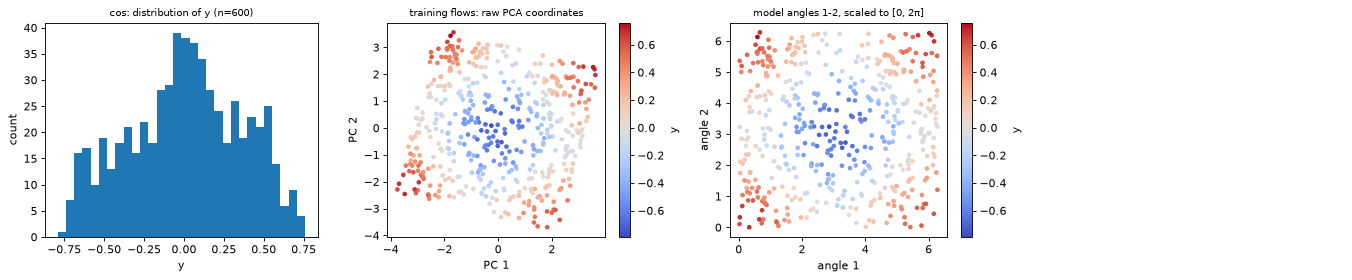

=== cos (J = 6 model inputs) ===  source: generated (y = 0.7 mean_j cos x_j + noise)
dataset shape: (600, 6) | feature names: ['x1', 'x2', 'x3', 'x4', 'x5', 'x6'] 
target y (regression): mean -0.003, std 0.209, min -0.683, max 0.652


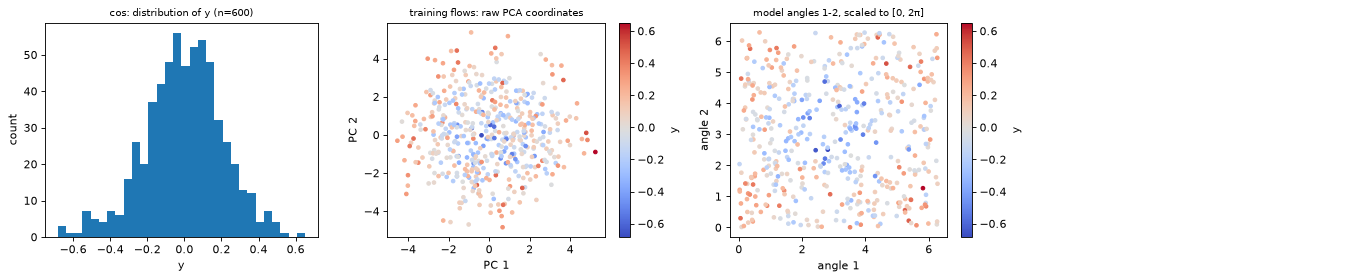

=== mnist (J = 6 model inputs) ===  source: huggingface:ylecun/mnist
dataset shape: (600, 784) | feature names: ['pixel_0', 'pixel_1', 'pixel_2', 'pixel_3', 'pixel_4', 'pixel_5', 'pixel_6', 'pixel_7'] ...
original label values and counts: {3: 300, 5: 300} -> model target -1/+1


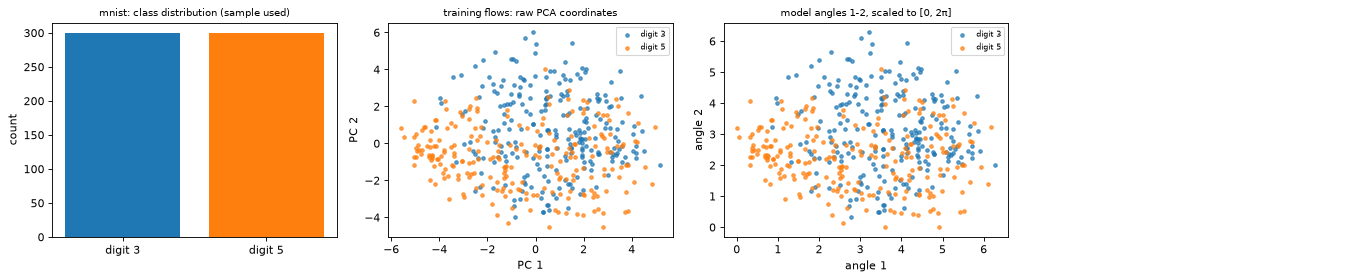

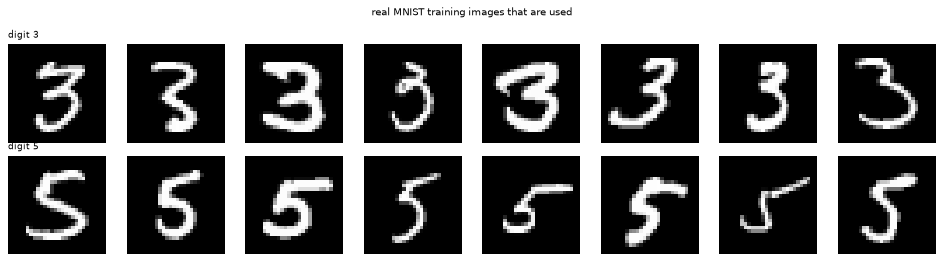

=== fraud (J = 6 model inputs) ===  source: huggingface:David-Egea/Creditcard-fraud-detection (Kaggle mlg-ulb)
dataset shape: (600, 30) | feature names: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7'] ...
original label values and counts: {0: 300, 1: 300} -> model target -1/+1


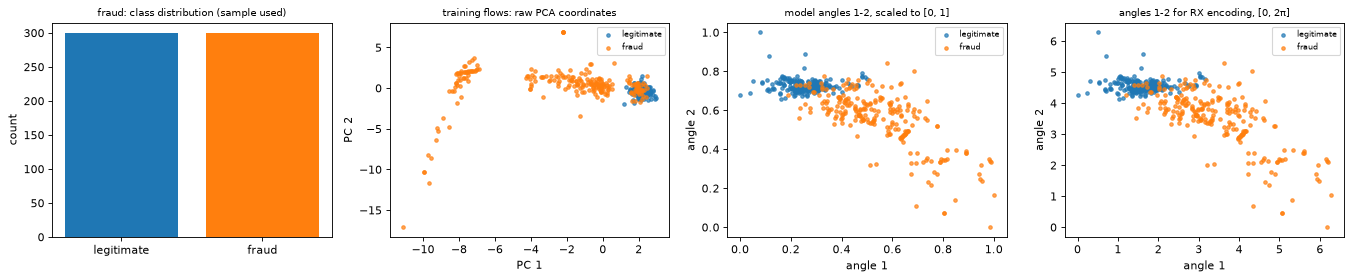

full public dataset (before the class-balanced sample): {'rows': 284807, 'columns': 31, 'legit': 284315, 'fraud': 492}
model features: the 6 most discriminative standardised columns (F-test on the training split): ['V4', 'V10', 'V11', 'V12', 'V14', 'V16']


In [9]:
def describe(key, J):
    d = DATA[(key, J)]
    X, y = d["X"], d["y"]
    print(f"=== {key} (J = {J} model inputs) ===  source: {d['source']}")
    print("dataset shape:", X.shape, "| feature names:", d["names"][:8], "..." if len(d["names"]) > 8 else "")
    if d["labels"] is None:
        print("target y (regression): mean %.3f, std %.3f, min %.3f, max %.3f" % (y.mean(), y.std(), y.min(), y.max()))
    else:
        vals, cnt = np.unique(d["labels"], return_counts=True)
        print("original label values and counts:", dict(zip(vals.tolist(), cnt.tolist())), "-> model target -1/+1")

# train/test split used only for the plots (the pipeline is fitted on the training part)
def split_idx(n, seed=SEED, test=0.2):
    idx = np.random.default_rng(seed).permutation(n)
    cut = int(n * (1 - test))
    return idx[:cut], idx[cut:]

def scatter_panel(ax, Z, d, title, xl, yl):
    if d["labels"] is None:                                  # regression target: continuous colour
        sc = ax.scatter(Z[:, 0], Z[:, 1], c=d["y"][ax._tr], s=10, cmap="coolwarm"); plt.colorbar(sc, ax=ax, label="y")
    else:
        lab = d["labels"][ax._tr]
        for v in np.unique(lab):
            ax.scatter(Z[lab == v, 0], Z[lab == v, 1], s=10, alpha=0.7, label=f"{CLASS_NAMES[(d['key'])].get(int(v), v)}")
        ax.legend(fontsize=7)
    ax.set_title(title, fontsize=9); ax.set_xlabel(xl); ax.set_ylabel(yl)

CLASS_NAMES = {"mnist": {MNIST_PAIR[0]: f"digit {MNIST_PAIR[0]}", MNIST_PAIR[1]: f"digit {MNIST_PAIR[1]}"},
               "fraud": {0: "legitimate", 1: "fraud"}, "cos": {}}
for k, d in DATA.items():
    d["key"] = k[0]

shown = [("cos", 2), ("cos", 6), ("mnist", 6), ("fraud", 6)]
for key, J in shown:
    describe(key, J)
    d = DATA[(key, J)]
    tr, te = split_idx(len(d["y"]))
    fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
    # (a) distribution of the real target / classes
    if d["labels"] is None:
        axes[0].hist(d["y"], bins=30, color="tab:blue"); axes[0].set_xlabel("y"); axes[0].set_ylabel("count"); axes[0].set_title(f"{key}: distribution of y (n={len(d['y'])})", fontsize=9)
    else:
        vals, cnt = np.unique(d["labels"], return_counts=True)
        axes[0].bar([CLASS_NAMES[key][int(v)] for v in vals], cnt, color=["tab:blue", "tab:orange"]); axes[0].set_ylabel("count"); axes[0].set_title(f"{key}: class distribution (sample used)", fontsize=9)
    # (b) raw 2-D PCA coordinates, PCA fitted on the training split
    Xs = StandardScaler().fit(d["X"][tr]).transform(d["X"]) if key == "fraud" else d["X"]
    p2 = PCA(2, random_state=SEED).fit(Xs[tr]); Zraw = p2.transform(Xs[tr])
    for a in axes[1:]:
        a._tr = tr
    scatter_panel(axes[1], Zraw, d, "training flows: raw PCA coordinates", "PC 1", "PC 2")
    # (c) the angles the model actually receives: first two angles (pipeline fitted on the training split)
    hi_main = ANGLE_HI["zz"] if key == "fraud" else ANGLE_HI["rx"]
    pipe = AnglePipe(key, J, hi_main).fit(d["X"][tr], d["y"][tr]); A = pipe.transform(d["X"][tr])
    scatter_panel(axes[2], A[:, :2], d, f"model angles 1-2, scaled to [0, {'2π' if hi_main > 1.5 else '1'}]", "angle 1", "angle 2")
    if key == "fraud":                                       # same features for the RX-encoded fraud model: [0, 2π]
        pipe2 = AnglePipe(key, J, ANGLE_HI["rx"]).fit(d["X"][tr], d["y"][tr]); A2 = pipe2.transform(d["X"][tr])
        scatter_panel(axes[3], A2[:, :2], d, "angles 1-2 for RX encoding, [0, 2π]", "angle 1", "angle 2")
    else:
        axes[3].axis("off")
    plt.tight_layout(); plt.show()
    if key == "mnist":
        fig, axes = plt.subplots(2, 8, figsize=(12, 3.3))
        for r, dgt in enumerate(MNIST_PAIR):
            ids = np.where(d["labels"] == dgt)[0][:8]
            for c, i in enumerate(ids):
                axes[r, c].imshow(d["X"][i].reshape(28, 28), cmap="gray"); axes[r, c].axis("off")
            axes[r, 0].set_title(f"digit {dgt}", fontsize=8, loc="left")
        plt.suptitle("real MNIST training images that are used", fontsize=9); plt.tight_layout(); plt.show()
    if key == "fraud":
        print("full public dataset (before the class-balanced sample):", fmeta)
        print("model features: the 6 most discriminative standardised columns (F-test on the training split):",
              [d["names"][i] for i in pipe.sel.get_support(indices=True)])

## Quantum Circuit Architecture

The four architectures are drawn below as the Qiskit circuits that the simulator executes (with a final measurement of every qubit; the model output is the average of the measured $Z$ values). Each drawing is followed by its qubit count, depth and number of trainable parameters.
The paper's Fig. 6 gives only drawings, so the exact gate placement is a **CHOICE** (see the table at the top): *Simple* (no entanglement), *Simple Entangled*, *Complex* (EfficientSU2) and *ZZEfficient* (ZZFeatureMap + EfficientSU2). The first $J$ parameters of every circuit encode the data $x$; the rest ($\theta$, $M$ of them) are trained and are the entries of the shared gradient.
The ZZFeatureMap appears as Hadamard, phase (P) and CNOT gates.

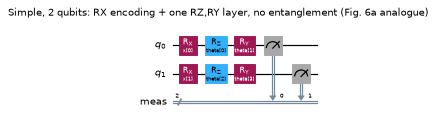

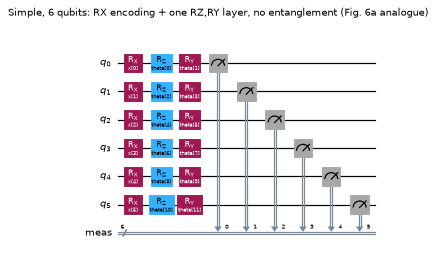

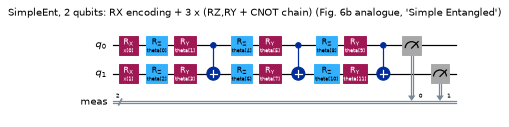

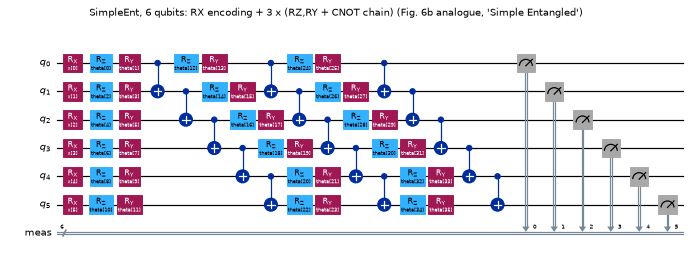

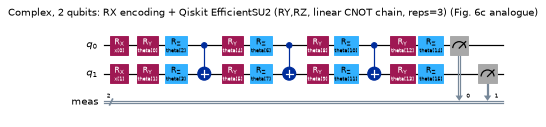

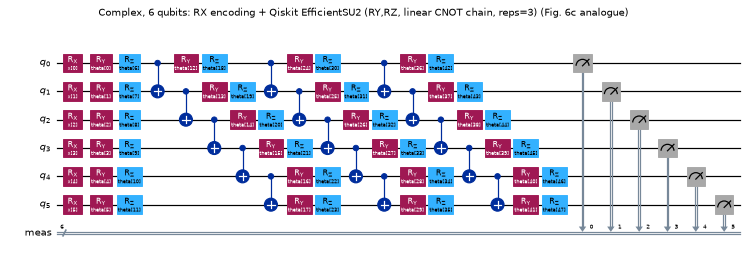

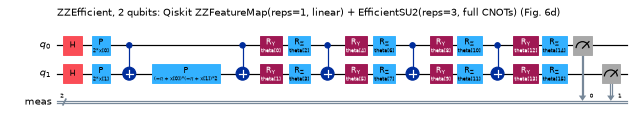

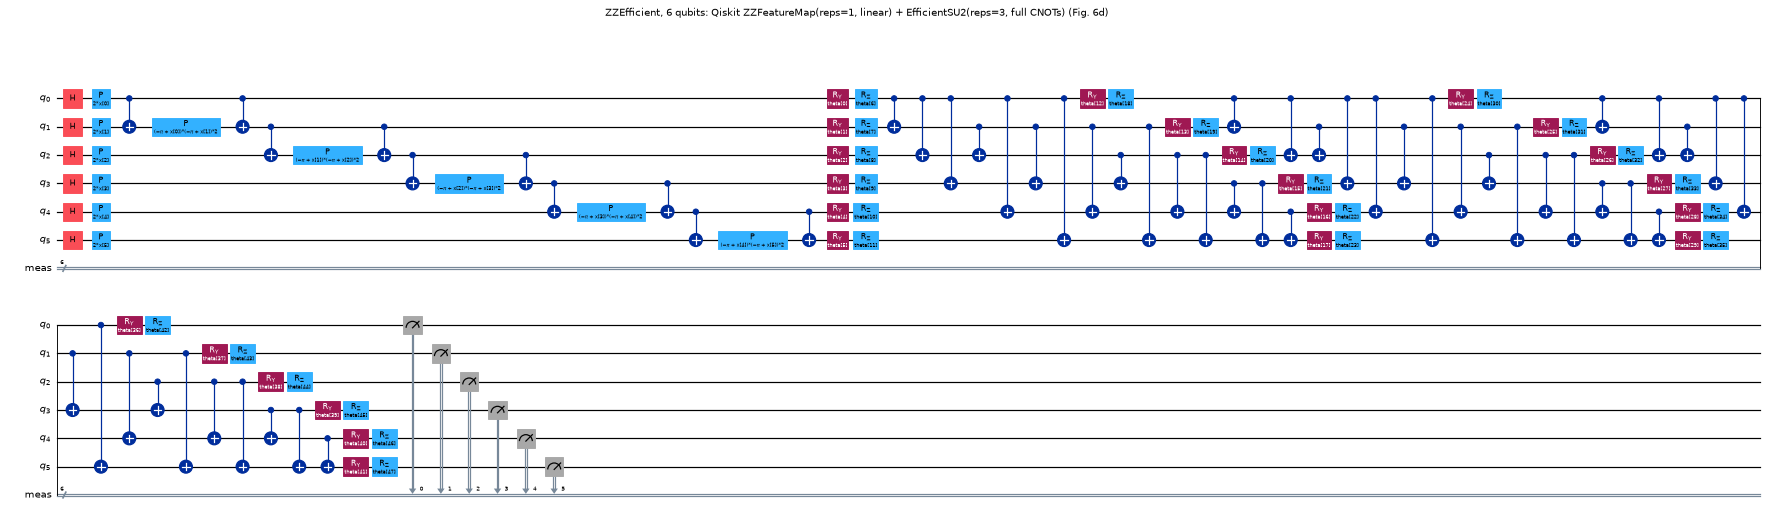

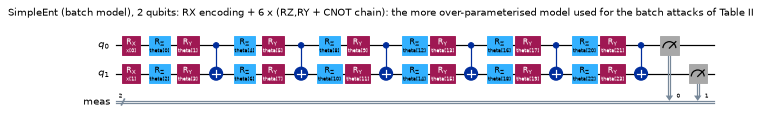

,architecture,qubits,depth,encoding_inputs,trainable_parameters,two_qubit_gates
0,Simple,2,3,2,4,0
1,Simple,6,3,6,12,0
2,SimpleEnt,2,10,2,12,3
3,SimpleEnt,6,16,6,36,15
4,Complex,2,12,2,16,3
5,Complex,6,18,6,48,15
6,ZZEfficient,2,16,2,16,5
7,ZZEfficient,6,46,6,48,55
8,SimpleEnt (batch model),2,19,2,24,6


In [10]:
ARCHS = ["Simple", "SimpleEnt", "Complex", "ZZEfficient"]
ARCH_NOTE = {"Simple": "RX encoding + one RZ,RY layer, no entanglement (Fig. 6a analogue)",
             "SimpleEnt": "RX encoding + 3 x (RZ,RY + CNOT chain) (Fig. 6b analogue, 'Simple Entangled')",
             "Complex": "RX encoding + Qiskit EfficientSU2 (RY,RZ, linear CNOT chain, reps=3) (Fig. 6c analogue)",
             "ZZEfficient": f"Qiskit ZZFeatureMap(reps={ZZ_REPS}, {ZZ_ENT}) + EfficientSU2(reps=3, full CNOTs) (Fig. 6d)",
             "SimpleEnt (batch model)": "RX encoding + 6 x (RZ,RY + CNOT chain): the more over-parameterised model used for the batch attacks of Table II"}
rows = []
for arch in ARCHS:
    for J in (2, 6):
        m = make_model(arch, J)
        qc = m.qiskit_circuit()
        full = qc                                                         # already gate-level: H, P, CNOT of the ZZFeatureMap, RY, RZ, CNOT of the ansatz
        meas = full.copy(); meas.measure_all()                            # <O> = mean of the measured Z outcomes
        rows.append(dict(architecture=arch, qubits=J, depth=full.depth(), encoding_inputs=J, trainable_parameters=m.M,
                         two_qubit_gates=int(sum(1 for i in full.data if i.operation.num_qubits == 2 and i.operation.name != "barrier"))))
        fig = meas.draw("mpl", fold=45 if J == 2 else 60, scale=0.55, plot_barriers=False)
        fig.suptitle(f"{arch}, {J} qubits: {ARCH_NOTE[arch]}", fontsize=9, y=1.0)
        display(fig)                                                      # Qiskit closes its figure, so show the returned object
# the batch-attack model of Table II has 6 layers instead of 3
m = make_model("SimpleEnt", 2, layers=6); qc = m.qiskit_circuit(); meas = qc.copy(); meas.measure_all()
rows.append(dict(architecture="SimpleEnt (batch model)", qubits=2, depth=qc.depth(), encoding_inputs=2, trainable_parameters=m.M,
                 two_qubit_gates=int(sum(1 for i in qc.data if i.operation.num_qubits == 2 and i.operation.name != "barrier"))))
fig = meas.draw("mpl", fold=45, scale=0.55, plot_barriers=False); fig.suptitle("SimpleEnt (batch model), 2 qubits: " + ARCH_NOTE["SimpleEnt (batch model)"], fontsize=9, y=1.0); display(fig)
display(pd.DataFrame(rows))

In [11]:
# ---- the fast simulator really executes these circuits: compare with Qiskit's exact Statevector ----
from qiskit.quantum_info import Statevector, SparsePauliOp
chk_rng = np.random.default_rng(SEED)
out = []
for arch in ARCHS:
    for J in (2, 6):
        m = make_model(arch, J); qc = m.qiskit_circuit()
        obs = SparsePauliOp.from_list([("I" * (J - 1 - j) + "Z" + "I" * j, 1.0 / J) for j in range(J)])      # mean of Z_j
        theta = chk_rng.uniform(0, TWO_PI, m.M)
        Xc = chk_rng.uniform(0, TWO_PI, (3, J))
        ref = np.array([Statevector(m.bind(qc, xv, theta)).expectation_value(obs).real for xv in Xc])
        d_pred = np.abs(ref - m.predict(Xc, theta)).max()
        # parameter-shift rule evaluated on the Qiskit circuits (2M circuits) versus the simulator's gradient
        m.set_theta(theta)
        gq = np.zeros(m.M)
        ks = list(range(m.M)) if J <= 3 else sorted(chk_rng.choice(m.M, 8, replace=False).tolist())       # 6 qubits: 8 random parameters
        for k in ks:
            tp, tm = theta.copy(), theta.copy(); tp[k] += np.pi / 2; tm[k] -= np.pi / 2
            gq[k] = 0.5 * (Statevector(m.bind(qc, Xc[0], tp)).expectation_value(obs).real - Statevector(m.bind(qc, Xc[0], tm)).expectation_value(obs).real)
        d_grad = np.abs(gq[ks] - m.grad(Xc[:1])[0][ks]).max()
        d_fast = np.abs(m.grad_dense(Xc) - m.grad(Xc)).max()
        assert d_pred < 1e-10 and d_grad < 1e-10 and d_fast < 1e-10, (arch, J, d_pred, d_grad, d_fast)
        out.append(dict(architecture=arch, qubits=J, params=m.M, max_err_expectation=d_pred, max_err_param_shift_grad=d_grad, max_err_fourier_form=d_fast))
display(pd.DataFrame(out).style.format({"max_err_expectation": "{:.1e}", "max_err_param_shift_grad": "{:.1e}", "max_err_fourier_form": "{:.1e}"}))
print("OK: the simulator, its parameter-shift gradient and the trigonometric form all agree with the drawn Qiskit circuits to ~1e-15.")

,architecture,qubits,params,max_err_expectation,max_err_param_shift_grad,max_err_fourier_form
0,Simple,2,4,5.6e-17,3.3e-16,1.1e-16
1,Simple,6,12,2.8e-16,9.7e-17,1.1e-16
2,SimpleEnt,2,12,3.1e-16,2.3e-16,2.2e-16
3,SimpleEnt,6,36,8.3e-17,6.9e-17,1.8e-16
4,Complex,2,16,2.2e-16,1.6e-16,8.3e-17
5,Complex,6,48,2.4e-16,6.2e-17,8.3e-17
6,ZZEfficient,2,16,2.2e-16,2.8e-16,0.0e+00
7,ZZEfficient,6,48,1.7e-16,2.7e-16,0.0e+00


OK: the simulator, its parameter-shift gradient and the trigonometric form all agree with the drawn Qiskit circuits to ~1e-15.


## 4. Training the VQNNs (Table I)

The attack only makes sense against models that are *trainable* ("as long as the model is trainable", paper Section I), so the paper first shows that its VQNNs reach reasonable accuracy. We train all twelve models of Table I with the MSE loss, using full-batch Adam on the exact gradients, with $k$-fold cross-validation (pre-processing re-fitted on every training fold). The regression score is $R^2$, the classification score the balanced accuracy of the sign of $\hat y$.
Then the same inputs are given to classical baselines (SVR / SVC with RBF kernel and random forests) to see what a good classical model achieves on the identical reduced features.

In [12]:
def train_vqnn(mdl, X, y, epochs=150, lr=0.05, seed=0, noise_sigma=0.0, theta0=None):
    """Full-batch Adam on the MSE loss between y_hat and y (all models of the paper use the MSE loss).
    noise_sigma > 0 adds N(0, sigma^2) to every component of the parameter gradient before the update: the Gaussian
    'differential-privacy' noise of the paper's Section V-D, applied here during training (CHOICE)."""
    g = torch.Generator().manual_seed(seed)
    theta = (torch.as_tensor(theta0, dtype=torch.float64).clone() if theta0 is not None
             else (torch.rand(mdl.M, generator=g, dtype=torch.float64) * 2 - 1) * np.pi)   # CHOICE: theta ~ U(-pi, pi)
    theta.requires_grad_(True)
    opt = torch.optim.Adam([theta], lr=lr)
    Phi = torch.as_tensor(mdl.phi(X)); yt = torch.as_tensor(y, dtype=torch.float64)
    for ep in range(epochs):
        opt.zero_grad()
        loss = ((mdl.predict_t(Phi, theta) - yt) ** 2).mean()
        loss.backward()
        if noise_sigma > 0:
            theta.grad = theta.grad + noise_sigma * torch.randn(mdl.M, generator=g, dtype=torch.float64)
        opt.step()
    return theta.detach().numpy()

def score(pred, y, task):
    """R^2 for the regression task, balanced accuracy (decision at 0) for the classification tasks, as in Table I."""
    return r2_score(y, pred) if task == "reg" else balanced_accuracy_score(y > 0, pred > 0)

def cv_row(key, arch, J, folds, epochs, seed=SEED):
    """k-fold cross-validation of one Table-I row; preprocessing is re-fitted on every training fold."""
    d = DATA[(key, J)]
    X, y = d["X"], d["y"]
    hi = ANGLE_HI["zz" if arch == "ZZEfficient" else "rx"]
    spl = (KFold(folds, shuffle=True, random_state=seed).split(X) if d["task"] == "reg"
           else StratifiedKFold(folds, shuffle=True, random_state=seed).split(X, y > 0))
    tr_s, te_s, last = [], [], None
    for f, (tr, te) in enumerate(spl):
        pipe = AnglePipe(key, J, hi).fit(X[tr], y[tr])
        mdl = make_model(arch, J)
        theta = train_vqnn(mdl, pipe.transform(X[tr]), y[tr], epochs=epochs, lr=TRAIN_LR, seed=seed + f)
        tr_s.append(score(mdl.predict(pipe.transform(X[tr]), theta), y[tr], d["task"]))
        te_s.append(score(mdl.predict(pipe.transform(X[te]), theta), y[te], d["task"]))
        last = (mdl, theta, pipe)
    return np.mean(tr_s), np.std(tr_s), np.mean(te_s), np.std(te_s), last

In [13]:
# ---- Table I of the paper: VQNN training performance (train / test, mean over the cross-validation folds) ----
TABLE1 = [  # dataset, paper's model name, our architecture, J, metric, paper train %, paper test %
    ("cos", "Simple", "Simple", 2, "R2", 99, 96), ("cos", "Simple", "Simple", 6, "R2", 98, 94),
    ("cos", "Complex", "Complex", 2, "R2", 99, 98), ("cos", "Complex", "Complex", 6, "R2", 99, 95),
    ("mnist", "Simple", "Simple", 2, "BalAcc", 89, 80), ("mnist", "Simple", "Simple", 6, "BalAcc", 91, 81),
    ("mnist", "Complex", "Complex", 2, "BalAcc", 84, 81), ("mnist", "Complex", "Complex", 6, "BalAcc", 83, 80),
    ("fraud", "Simple (Entangled)", "SimpleEnt", 2, "BalAcc", 88, 86), ("fraud", "Simple (Entangled)", "SimpleEnt", 6, "BalAcc", 85, 83),
    ("fraud", "Complex ZZEfficient", "ZZEfficient", 2, "BalAcc", 84, 81), ("fraud", "Complex ZZEfficient", "ZZEfficient", 6, "BalAcc", 80, 78),
]
t0 = time.time()
t1_rows, TRAINED = [], {}
for key, pname, arch, J, metric, p_tr, p_te in TABLE1:
    tr_m, tr_s, te_m, te_s, last = cv_row(key, arch, J, CV_FOLDS, EPOCHS)
    TRAINED[(key, arch, J)] = last
    t1_rows.append(dict(dataset=key, model=pname, qubits=J, metric=metric, paper_train=p_tr, paper_test=p_te,
                        notebook_train=round(100 * tr_m, 1), notebook_test=round(100 * te_m, 1), test_std=round(100 * te_s, 1)))
    print(f"{key:6s} {pname:20s} J={J}: train {100*tr_m:5.1f}  test {100*te_m:5.1f} +- {100*te_s:.1f}   (paper {p_tr}/{p_te})   [{time.time()-t0:.0f}s]", flush=True)
TABLE1_DF = pd.DataFrame(t1_rows)
display(TABLE1_DF)

cos    Simple               J=2: train  97.9  test  97.7 +- 0.3   (paper 99/96)   [15s]


cos    Simple               J=6: train  94.3  test  94.0 +- 0.4   (paper 98/94)   [37s]


cos    Complex              J=2: train  97.9  test  97.7 +- 0.3   (paper 99/98)   [46s]


cos    Complex              J=6: train  90.1  test  88.8 +- 1.5   (paper 99/95)   [140s]


mnist  Simple               J=2: train  67.9  test  67.2 +- 5.5   (paper 89/80)   [148s]


...

fraud  Simple (Entangled)   J=2: train  89.2  test  89.2 +- 1.4   (paper 88/86)   [288s]


fraud  Simple (Entangled)   J=6: train  90.2  test  90.2 +- 2.1   (paper 85/83)   [377s]


fraud  Complex ZZEfficient  J=2: train  90.8  test  90.5 +- 2.0   (paper 84/81)   [388s]


fraud  Complex ZZEfficient  J=6: train  88.2  test  87.0 +- 1.7   (paper 80/78)   [543s]


,dataset,model,qubits,metric,paper_train,paper_test,notebook_train,notebook_test,test_std
0,cos,Simple,2,R2,99,96,97.9,97.7,0.3
1,cos,Simple,6,R2,98,94,94.3,94.0,0.4
2,cos,Complex,2,R2,99,98,97.9,97.7,0.3
3,cos,Complex,6,R2,99,95,90.1,88.8,1.5
4,mnist,Simple,2,BalAcc,89,80,67.9,67.2,5.5
5,mnist,Simple,6,BalAcc,91,81,85.8,83.3,2.6
6,mnist,Complex,2,BalAcc,84,81,68.9,67.5,3.8
7,mnist,Complex,6,BalAcc,83,80,82.3,81.7,3.1
8,fraud,Simple (Entangled),2,BalAcc,88,86,89.2,89.2,1.4
9,fraud,Simple (Entangled),6,BalAcc,85,83,90.2,90.2,2.1


In [14]:
# ---- classical baselines on exactly the same reduced inputs (angles) and the same 80/20 split ----
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
b_rows = []
for key, J in [("cos", 2), ("cos", 6), ("mnist", 2), ("mnist", 6), ("fraud", 2), ("fraud", 6)]:
    d = DATA[(key, J)]
    tr, te = split_idx(len(d["y"]))
    pipe = AnglePipe(key, J, ANGLE_HI["rx"]).fit(d["X"][tr], d["y"][tr])
    Atr, Ate = pipe.transform(d["X"][tr]), pipe.transform(d["X"][te])
    ytr, yte = d["y"][tr], d["y"][te]
    if d["task"] == "reg":
        for name, clf in [("SVR (rbf)", SVR(C=10)), ("RandomForest", RandomForestRegressor(200, random_state=SEED))]:
            clf.fit(Atr, ytr); b_rows.append(dict(dataset=key, J=J, model=name, metric="R2", train=r2_score(ytr, clf.predict(Atr)), test=r2_score(yte, clf.predict(Ate))))
    else:
        for name, clf in [("SVC (rbf)", SVC(C=10)), ("RandomForest", RandomForestClassifier(200, random_state=SEED))]:
            clf.fit(Atr, ytr > 0)
            b_rows.append(dict(dataset=key, J=J, model=name, metric="BalAcc", train=balanced_accuracy_score(ytr > 0, clf.predict(Atr)),
                               test=balanced_accuracy_score(yte > 0, clf.predict(Ate))))
BASE_DF = pd.DataFrame(b_rows)
display(BASE_DF.style.format({"train": "{:.3f}", "test": "{:.3f}"}))

,dataset,J,model,metric,train,test
0,cos,2,SVR (rbf),R2,0.977,0.978
1,cos,2,RandomForest,R2,0.994,0.976
2,cos,6,SVR (rbf),R2,0.902,0.821
3,cos,6,RandomForest,R2,0.956,0.622
4,mnist,2,SVC (rbf),BalAcc,0.719,0.703
5,mnist,2,RandomForest,BalAcc,1.000,0.645
6,mnist,6,SVC (rbf),BalAcc,0.985,0.927
7,mnist,6,RandomForest,BalAcc,1.000,0.936
8,fraud,2,SVC (rbf),BalAcc,0.943,0.864
9,fraud,2,RandomForest,BalAcc,1.000,0.862


## 5. Attacking the shared gradients (Table II)

For each row of Table II: the attacked model has **all weights equal to 1** (the paper's default), the "client" holds a real data sample (or a batch of 2 / 3 samples whose gradients are summed before sharing), and the attacker starts from a random point at least 0.005 away. Ten (FAST: ten for 2-D, four for 6-D) such attacks per row are run **twice from identical secrets and starting points**: once with the adaptive moving-average filter,
once with the Kalman filter added. We report the *one-shot success rate* (MSE $\le0.005$ within the iteration budget) and the mean MSE of the successful attacks with its standard error, next to the paper's numbers.
Attention: with 10 trials a success rate has a binomial standard error of up to 16 percentage points, so differences of 20 points are within noise.

In [15]:
def atk_params(arch, J):
    fam = "zz" if arch == "ZZEfficient" else "rx"
    return dict(lr=ATK_LR[(fam, J)], h=ATK_H[fam], N0=(32 if (fam, J) == ("zz", 6) else ATK_N0), thr=ATK_THR)   # N0 = 32 halves the cost of the dense model

def K_for(arch, J):
    return K_ZZ6 if (arch == "ZZEfficient" and J == 6) else K_ATTACK[J]

def angle_pool(key, arch, J):
    """The 'private' data of a client: real training samples as model angles (pipeline fitted on the training split only)."""
    d = DATA[(key, J)]
    tr, _ = split_idx(len(d["y"]))
    hi = ANGLE_HI["zz" if arch == "ZZEfficient" else "rx"]
    return AnglePipe(key, J, hi).fit(d["X"][tr], d["y"][tr]).transform(d["X"][tr]), hi

def make_targets(pool, hi, b, n, seed):
    """n attacks: a batch of b real samples x (the secret) and a random starting point x' for each (constrained to be >= 0.005 away)."""
    r = np.random.default_rng(seed)
    out = []
    for _ in range(n):
        x = pool[r.choice(len(pool), b, replace=False)]
        while True:
            x0 = r.uniform(0, hi, x.shape)
            if circ_mse(x0.ravel(), x.ravel()) >= SUCCESS_MSE: break
        out.append((x, x0))
    return out

def summarise(res):
    ok = [r["mse"] for r in res if r["success"]]
    allm = np.array([r["mse"] for r in res])
    return dict(success_pct=100 * np.mean([r["success"] for r in res]),
                mse_success=np.mean(ok) if ok else np.nan,
                se_success=(np.std(ok, ddof=1) / np.sqrt(len(ok)) if len(ok) > 1 else np.nan),
                median_mse_all=np.median(allm), trials=len(res))

# ---- Table II rows: (label, dataset, architecture, J, batch, ansatz layers, paper: one-shot success % and MSE for the adaptive and the Kalman attack) ----
TABLE2 = [
    ("VQNN 2-qubits Cosine Complex", "cos", "Complex", 2, 1, 3, (100, 2e-4), (100, 2e-4)),
    ("VQNN 6-qubits Cosine Complex", "cos", "Complex", 6, 1, 3, (40, 5e-4), (70, 3e-4)),
    ("VQNN 6-dims Fraud ZZEfficient", "fraud", "ZZEfficient", 6, 1, 3, (50, 7e-4), (70, 3e-4)),
    ("VQNN 6-dims MNIST Complex", "mnist", "Complex", 6, 1, 3, (40, 5e-4), (80, 2e-4)),
    ("VQNN Batch size 2", "cos", "SimpleEnt", 2, 2, 6, (100, 5e-5), (100, 2e-5)),
    ("VQNN Batch size 3", "cos", "SimpleEnt", 2, 3, 6, (100, 2e-3), (100, 3e-3)),
]
ATTACKS = {}            # kept for the figures: ATTACKS[label] = {"plain": [...], "kalman": [...]}
t2_rows = []
t0 = time.time()
for ri, (label, key, arch, J, b, layers, p_ad, p_ka) in enumerate(TABLE2):
    n_tr = N_TRIALS_BATCH if b > 1 else (N_TRIALS_2D if J == 2 else (N_TRIALS_ZZ6 if arch == "ZZEfficient" else N_TRIALS_6D))
    K = K_for(arch, J)
    mdl = make_model(arch, J, layers=layers); mdl.set_theta(np.ones(mdl.M))              # paper: all weights are 1 (unit vector)
    pool, hi = angle_pool(key, arch, J)
    targets = make_targets(pool, hi, b, n_tr, seed=SEED + 100 * ri)       # identical secrets and starts for both attacks
    atk = atk_params(arch, J)
    res_p = run_trials(mdl, targets, atk, kalman=False, K=K)
    res_k = run_trials(mdl, targets, atk, kalman=True, K=K)
    ATTACKS[label] = dict(plain=res_p, kalman=res_k, model=mdl, b=b, J=J, arch=arch)
    sp, sk = summarise(res_p), summarise(res_k)
    t2_rows.append({"model": label, "params M": mdl.M, "trials": n_tr,
                    "paper adaptive %": p_ad[0], "notebook adaptive %": sp["success_pct"], "paper adaptive MSE": p_ad[1],
                    "notebook adaptive MSE (successful)": sp["mse_success"], "+-SE": sp["se_success"],
                    "paper Kalman %": p_ka[0], "notebook Kalman %": sk["success_pct"], "paper Kalman MSE": p_ka[1],
                    "notebook Kalman MSE (successful)": sk["mse_success"], "+-SE ": sk["se_success"]})
    print(f"{label:34s} M={mdl.M:3d} trials={n_tr:2d} | adaptive {sp['success_pct']:5.1f}%  Kalman {sk['success_pct']:5.1f}%   [{time.time()-t0:.0f}s]", flush=True)
TABLE2_DF = pd.DataFrame(t2_rows)
display(TABLE2_DF.style.format({c: "{:.1e}" for c in TABLE2_DF.columns if "MSE" in c or "SE" in c}, na_rep="-"))

VQNN 2-qubits Cosine Complex       M= 16 trials=10 | adaptive  90.0%  Kalman  80.0%   [3s]


VQNN 6-qubits Cosine Complex       M= 48 trials=10 | adaptive  50.0%  Kalman  30.0%   [23s]


VQNN 6-dims Fraud ZZEfficient      M= 48 trials=10 | adaptive  30.0%  Kalman   0.0%   [184s]


VQNN 6-dims MNIST Complex          M= 48 trials=10 | adaptive  70.0%  Kalman  50.0%   [203s]


VQNN Batch size 2                  M= 24 trials=10 | adaptive  90.0%  Kalman  90.0%   [210s]


VQNN Batch size 3                  M= 24 trials=10 | adaptive  90.0%  Kalman  60.0%   [224s]


,model,params M,trials,paper adaptive %,notebook adaptive %,paper adaptive MSE,notebook adaptive MSE (successful),+-SE,paper Kalman %,notebook Kalman %,paper Kalman MSE,notebook Kalman MSE (successful),+-SE
0,VQNN 2-qubits Cosine Complex,16,10,100,90.000000,2.0e-04,5.1e-09,1.3e-09,100,80.000000,2.0e-04,5.5e-09,1.4e-09
1,VQNN 6-qubits Cosine Complex,48,10,40,50.000000,5.0e-04,3.2e-09,8.5e-10,70,30.000000,3.0e-04,3.9e-09,9.3e-10
2,VQNN 6-dims Fraud ZZEfficient,48,10,50,30.000000,7.0e-04,4.6e-06,2.0e-06,70,0.000000,3.0e-04,-,-
3,VQNN 6-dims MNIST Complex,48,10,40,70.000000,5.0e-04,2.2e-09,4.1e-10,80,50.000000,2.0e-04,1.7e-09,3.7e-10
4,VQNN Batch size 2,24,10,100,90.000000,5.0e-05,1.8e-08,9.8e-09,100,90.000000,2.0e-05,5.5e-07,5.3e-07
5,VQNN Batch size 3,24,10,100,90.000000,2.0e-03,9.5e-04,5.3e-04,100,60.000000,3.0e-03,9.3e-05,9.1e-05


## 6. Re-drawing the paper's figures

* **Fig. 4 analogue** - the gradient-matching loss of the 2-qubit *Complex* model as a function of the guess $x'$: a landscape with many local minima, one of which is the secret.
* **Fig. 5 / 7 analogue** - the paths of all attacks of Table II in the plane (gradient loss, MSE to the secret). A path that ends at a small gradient loss *and* a small MSE has found the secret; a path that ends at a small gradient loss but a large MSE would be an input with the same gradient but a different value (not seen here); a path that stalls at a large gradient loss is trapped in a local minimum.
* **Fig. 8 / 9 analogues** - depth of the ansatz and window size / Kalman filter on the 2-qubit ZZEfficient model.
* **Appendix analogues (Figs. 15, 16, 17)** - long runs, random initial weights, a trained model - and an **ablation of the Kalman filter**.
* **The paper's central premise:** the same secrets and starting points, attacked with finite differences *without* the low-pass filter (window N = 1) and with L-BFGS-B on the gradient loss.

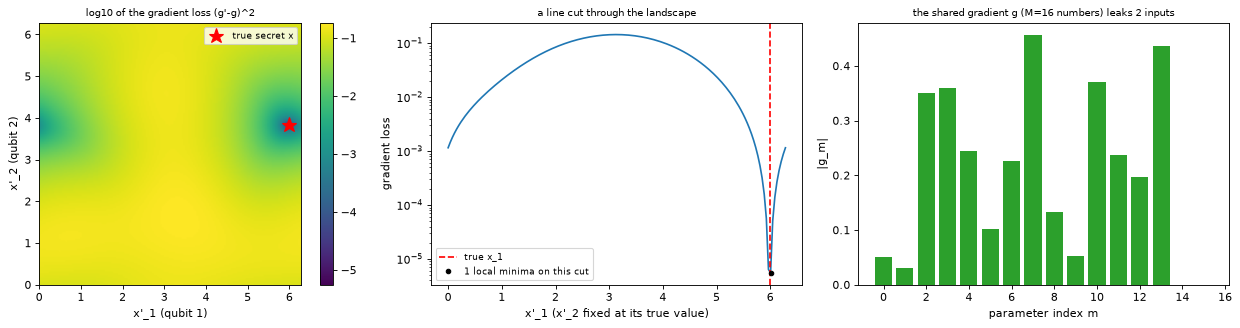

grid minima of the 2-D landscape (strict 4-neighbour): 1; global minimum cost on the grid: 5.56e-06 at x' = [6.01 3.83] (true [5.99 3.83])


In [16]:
# ---- Fig. 4 analogue: the gradient-loss landscape L(x') = mean (g'(x') - g)^2 of the 2-qubit Complex model ----
from scipy.signal import argrelmin
mdl = ATTACKS["VQNN 2-qubits Cosine Complex"]["model"]
tgt = make_targets(*angle_pool("cos", "Complex", 2), 1, 1, seed=SEED)[0][0]      # one secret sample x = (x1, x2)
g_star = grad_sum(mdl, tgt.ravel(), 1, 2)
G = 160
gx = np.linspace(0, TWO_PI, G)
XX, YY = np.meshgrid(gx, gx, indexing="ij")
pts = np.stack([XX.ravel(), YY.ravel()], axis=1)
L = ((mdl.grad(pts) - g_star[None, :]) ** 2).mean(1).reshape(G, G)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
im = ax[0].imshow(np.log10(L + 1e-12).T, origin="lower", extent=[0, TWO_PI, 0, TWO_PI], cmap="viridis")
ax[0].plot(*tgt.ravel(), "r*", ms=14, label="true secret x"); ax[0].legend(loc="upper right", fontsize=8)
ax[0].set_xlabel("x'_1 (qubit 1)"); ax[0].set_ylabel("x'_2 (qubit 2)"); ax[0].set_title("log10 of the gradient loss (g'-g)^2", fontsize=9); plt.colorbar(im, ax=ax[0])
i2 = int(np.argmin(np.abs(gx - tgt[0, 1])))
ax[1].plot(gx, L[:, i2], color="tab:blue"); ax[1].axvline(tgt[0, 0], color="r", ls="--", label="true x_1"); ax[1].set_yscale("log")
mins = argrelmin(L[:, i2])[0]
ax[1].plot(gx[mins], L[mins, i2], "ko", ms=4, label=f"{len(mins)} local minima on this cut")
ax[1].set_xlabel("x'_1 (x'_2 fixed at its true value)"); ax[1].set_ylabel("gradient loss"); ax[1].legend(fontsize=8); ax[1].set_title("a line cut through the landscape", fontsize=9)
nloc = int(((L[1:-1, 1:-1] < L[:-2, 1:-1]) & (L[1:-1, 1:-1] < L[2:, 1:-1]) & (L[1:-1, 1:-1] < L[1:-1, :-2]) & (L[1:-1, 1:-1] < L[1:-1, 2:])).sum())
# frequency content: the gradient of a RX-encoded VQNN is a trigonometric polynomial of degree 1 in each x_j
ax[2].bar(range(mdl.M), np.abs(g_star), color="tab:green"); ax[2].set_xlabel("parameter index m"); ax[2].set_ylabel("|g_m|")
ax[2].set_title(f"the shared gradient g (M={mdl.M} numbers) leaks 2 inputs", fontsize=9)
plt.tight_layout(); plt.show()
print(f"grid minima of the 2-D landscape (strict 4-neighbour): {nloc}; global minimum cost on the grid: {L.min():.2e} at x' = {pts[np.argmin(L.ravel())].round(2)} (true {tgt.ravel().round(2)})")

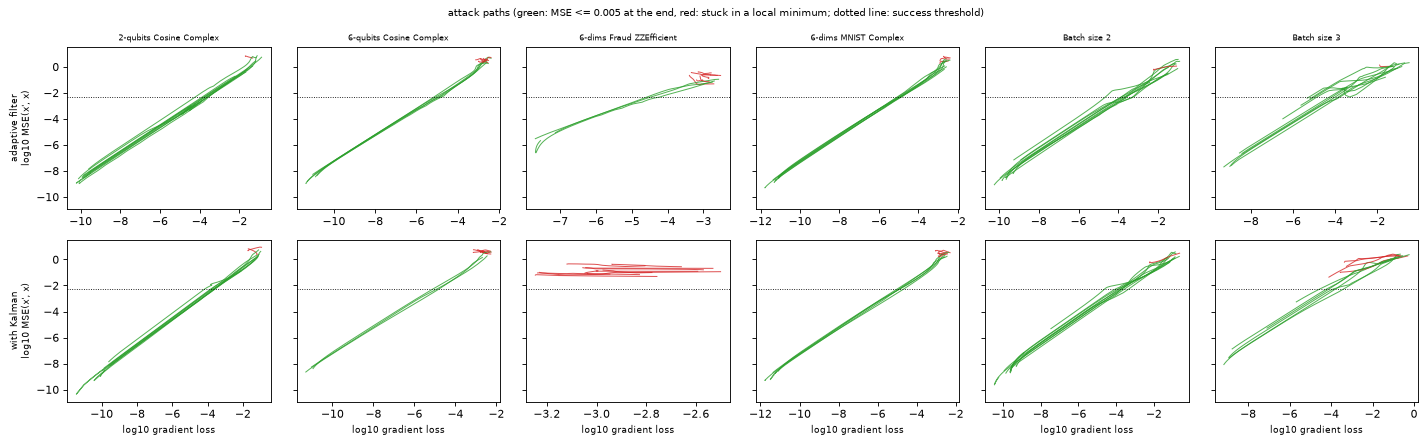

VQNN 6-dims MNIST Complex: 5 of 10 Kalman attacks reached MSE <= 0.005; best final MSE = 5.24e-10


In [17]:
# ---- Fig. 5 / 7 analogue: attack paths, log10 MSE(x'_k, x) against the gradient loss (g'_k - g)^2, one line per attack ----
labels = list(ATTACKS)
fig, axes = plt.subplots(2, len(labels), figsize=(3.0 * len(labels), 5.6), sharey=True)
for c, lab in enumerate(labels):
    for r, mode in enumerate(["plain", "kalman"]):
        ax = axes[r, c]
        for tr in ATTACKS[lab][mode]:
            h = tr["hist"]
            ax.plot(np.log10(np.array(h["gloss"]) + 1e-30), np.log10(np.array(h["mse"]) + 1e-30), color=("tab:green" if tr["success"] else "tab:red"), lw=0.9, alpha=0.8)
        ax.axhline(np.log10(SUCCESS_MSE), color="k", ls=":", lw=0.8)
        if r == 0: ax.set_title(lab.replace("VQNN ", ""), fontsize=7)
        if c == 0: ax.set_ylabel(("adaptive filter" if mode == "plain" else "with Kalman") + "\nlog10 MSE(x', x)", fontsize=8)
        if r == 1: ax.set_xlabel("log10 gradient loss", fontsize=8)
plt.suptitle("attack paths (green: MSE <= 0.005 at the end, red: stuck in a local minimum; dotted line: success threshold)", fontsize=9)
plt.tight_layout(); plt.show()

# a quick numerical summary for one 6-dimensional row
lab6 = "VQNN 6-dims MNIST Complex"
ok = [t for t in ATTACKS[lab6]["kalman"] if t["success"]]
print(f"{lab6}: {len(ok)} of {len(ATTACKS[lab6]['kalman'])} Kalman attacks reached MSE <= {SUCCESS_MSE}; best final MSE = {min(t['mse'] for t in ATTACKS[lab6]['kalman']):.2e}")

,parameters,trials,reached_1e5,mean_iterations
0,8,10,6,15.333333
1,12,10,4,13.000000
2,16,10,3,6.666667
3,20,10,4,9.250000


,attack,success_pct,median_final_mse
0,adaptive N=16,70.0,0.000004
1,adaptive N=64,90.0,0.000002
2,Kalman N=16,80.0,0.000003
3,Kalman N=32,70.0,0.000003
4,Kalman N=64,60.0,0.000004


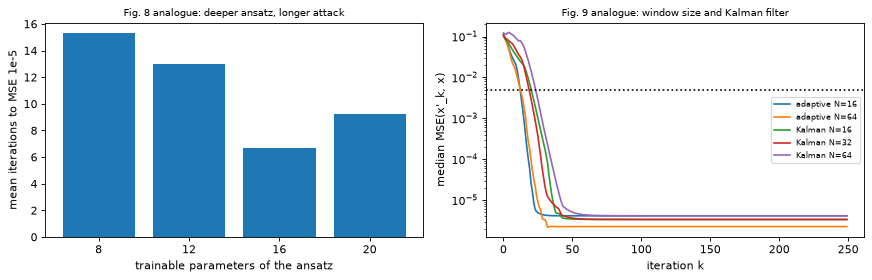

In [18]:
# ---- 2-qubit ZZEfficient model on Cosine-type and Fraud data: Fig. 8 (circuit depth) and Fig. 9 (filter window, Kalman) ----
hiZ = ANGLE_HI["zz"]
poolF2, _ = angle_pool("fraud", "ZZEfficient", 2)
poolC2 = np.random.default_rng(SEED).uniform(0, hiZ, (200, 2))          # cosine inputs on the same [0, 1] range as the ZZ models
def zz_targets(n, seed):
    half = (n + 1) // 2
    return make_targets(poolC2, hiZ, 1, half, seed) + make_targets(poolF2, hiZ, 1, n - half, seed + 1)

# --- Fig. 8: iterations needed to reach MSE 1e-5 for ansatz depths with 8, 12, 16, 20 parameters ---
f8 = []
for reps in (1, 2, 3, 4):
    m = make_model("ZZEfficient", 2, layers=reps); m.set_theta(np.ones(m.M))
    atk = dict(lr=ATK_LR[("zz", 2)], h=ATK_H["zz"], N0=ATK_N0, thr=ATK_THR)
    res = run_trials(m, zz_targets(N_FIG8, SEED + 7), atk, kalman=True, K=400, stop_mse=1e-5)
    its = [r["first_hit"] for r in res if r["mse"] <= 1e-5]
    f8.append(dict(parameters=m.M, trials=len(res), reached_1e5=len(its), mean_iterations=float(np.mean(its)) if its else np.nan))
F8 = pd.DataFrame(f8); display(F8)

# --- Fig. 9: Kalman attack with initial window N = 16, 32, 64 versus the plain adaptive attack with N = 16 and N = 64 ---
m2 = make_model("ZZEfficient", 2); m2.set_theta(np.ones(m2.M))
tg9 = zz_targets(N_FIG9, SEED + 9)
curves, f9 = {}, []
for name, kal, N0 in [("adaptive N=16", False, 16), ("adaptive N=64", False, 64), ("Kalman N=16", True, 16), ("Kalman N=32", True, 32), ("Kalman N=64", True, 64)]:
    atk = dict(lr=ATK_LR[("zz", 2)], h=ATK_H["zz"], N0=N0, thr=ATK_THR)
    res = run_trials(m2, tg9, atk, kalman=kal, K=FIG9_K)
    curves[name] = np.array([r["hist"]["mse"] for r in res])
    f9.append(dict(attack=name, success_pct=100 * np.mean([r["success"] for r in res]), median_final_mse=float(np.median([r["mse"] for r in res]))))
F9 = pd.DataFrame(f9); display(F9)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].bar(F8.parameters.astype(str), F8.mean_iterations, color="tab:blue"); ax[0].set_xlabel("trainable parameters of the ansatz"); ax[0].set_ylabel("mean iterations to MSE 1e-5")
ax[0].set_title("Fig. 8 analogue: deeper ansatz, longer attack", fontsize=9)
for name, arr in curves.items():
    ax[1].plot(np.median(arr, axis=0), label=name)
ax[1].set_yscale("log"); ax[1].axhline(SUCCESS_MSE, color="k", ls=":"); ax[1].set_xlabel("iteration k"); ax[1].set_ylabel("median MSE(x'_k, x)"); ax[1].legend(fontsize=7)
ax[1].set_title("Fig. 9 analogue: window size and Kalman filter", fontsize=9)
plt.tight_layout(); plt.show()

In [19]:
# ---- Appendix analogues (Fig. 15, 16, 17) and an ablation of the Kalman filter ----
mdl2 = ATTACKS["VQNN 2-qubits Cosine Complex"]["model"]
atk2 = atk_params("Complex", 2)
tg2 = make_targets(*angle_pool("cos", "Complex", 2), 1, 6, seed=SEED + 31)

# Fig. 15: more iterations drive the error down to the numerical floor (only the attacks that found the global basin)
long = run_trials(mdl2, tg2, atk2, kalman=True, K=700)
print("Fig. 15 analogue (K = 700): final MSE of 6 attacks:", ["%.1e" % r["mse"] for r in long])

# Fig. 16: random initial weights theta instead of all ones
rw = []
for s in range(4):
    th = np.random.default_rng(SEED + 40 + s).uniform(0, TWO_PI, mdl2.M)
    m = make_model("Complex", 2); m.set_theta(th)
    r = run_trials(m, make_targets(*angle_pool("cos", "Complex", 2), 1, 5, seed=SEED + 50 + s), atk2, kalman=True, K=K_ATTACK[2])
    rw.append(100 * np.mean([x["success"] for x in r]))
print("Fig. 16 analogue: success rate (%) with 4 different random weight vectors, 5 attacks each:", rw)

# Fig. 17: the gradient of a TRAINED model (Fraud, ZZEfficient, 6 inputs) is attacked as well
mt, th_t, pipe_t = TRAINED[("fraud", "ZZEfficient", 6)]
mt.set_theta(th_t)
dF = DATA[("fraud", 6)]; trF, _ = split_idx(len(dF["y"]))
poolT = pipe_t.transform(dF["X"][trF])
n_tr_t = N_FIG17
tgT = make_targets(poolT, ANGLE_HI["zz"], 1, n_tr_t, seed=SEED + 60)
resT = run_trials(mt, tgT, atk_params("ZZEfficient", 6), kalman=True, K=K_for("ZZEfficient", 6))
print(f"Fig. 17 analogue: trained 6-input ZZEfficient model, Kalman attack: success {100*np.mean([r['success'] for r in resT]):.0f}% of {n_tr_t}; final MSEs", ["%.1e" % r["mse"] for r in resT])

# Kalman ablation on the 6-qubit cosine row (cheap RX model, more trials)
mdl6 = ATTACKS["VQNN 6-qubits Cosine Complex"]["model"]
atk6 = atk_params("Complex", 6)
n_abl = 20 if FAST_MODE else 40
tg6 = make_targets(*angle_pool("cos", "Complex", 6), 1, n_abl, seed=SEED + 77)
abl = []
for name, kw, lrscale in [("adaptive filter (no Kalman)", dict(kalman=False), 1.0),
                          ("Kalman, zero initial state (as in the paper)", dict(kalman=True), 1.0),
                          ("Kalman, state initialised at x'_0", dict(kalman=True, kalman_init="x0"), 1.0),
                          ("no Kalman, learning rate x 0.62 (the Kalman gain)", dict(kalman=False), 0.62),
                          ("no Kalman, start x'_0 scaled by 2/3 (the first Kalman step)", dict(kalman=False, scale0=True), 1.0)]:
    kw = dict(kw); sc0 = kw.pop("scale0", False)
    tgs = [(x, 2 / 3 * x0) for x, x0 in tg6] if sc0 else tg6
    r = run_trials(mdl6, tgs, dict(atk6, lr=atk6["lr"] * lrscale), K=K_ATTACK[6], **kw)
    abl.append(dict(variant=name, success_pct=100 * np.mean([x["success"] for x in r]), trials=len(r)))
ABL = pd.DataFrame(abl); display(ABL)

Fig. 15 analogue (K = 700): final MSE of 6 attacks: ['1.1e-08', '1.2e-09', '5.9e-09', '6.9e+00', '6.3e-09', '8.5e+00']


Fig. 16 analogue: success rate (%) with 4 different random weight vectors, 5 attacks each: [np.float64(60.0), np.float64(80.0), np.float64(80.0), np.float64(100.0)]


Fig. 17 analogue: trained 6-input ZZEfficient model, Kalman attack: success 0% of 4; final MSEs ['8.4e-02', '1.5e-01', '2.6e-01', '4.1e-01']


,variant,success_pct,trials
0,adaptive filter (no Kalman),40.0,40
1,"Kalman, zero initial state (as in the paper)",32.5,40
2,"Kalman, state initialised at x'_0",37.5,40
3,"no Kalman, learning rate x 0.62 (the Kalman gain)",37.5,40
4,"no Kalman, start x'_0 scaled by 2/3 (the first...",40.0,40


In [20]:
# ---- Is the low-pass filter really needed? Same secrets and starting points as Table II, three ways of minimising the gradient loss ----
from scipy.optimize import minimize
nf_rows = []
for ri, (label, key, arch, J, b, layers, p_ad, p_ka) in enumerate(TABLE2):
    if label not in ("VQNN 2-qubits Cosine Complex", "VQNN 6-qubits Cosine Complex", "VQNN 6-dims MNIST Complex"):
        continue
    mdl = ATTACKS[label]["model"]
    pool, hi = angle_pool(key, arch, J)
    targets = make_targets(pool, hi, b, len(ATTACKS[label]["plain"]), seed=SEED + 100 * ri)      # same secrets/starts as Table II
    atk = atk_params(arch, J)
    r_nofilt = run_trials(mdl, targets, dict(atk, N0=1), kalman=False, K=K_ATTACK[J])                         # window N = 1: plain central differences
    r_filt = ATTACKS[label]["plain"]
    ok_lb = []
    for x, x0 in targets:
        g = grad_sum(mdl, x.ravel(), 1, J)
        f = lambda u: ((grad_sum(mdl, u, 1, J) - g) ** 2).mean()
        r = minimize(f, x0.ravel(), method="L-BFGS-B", bounds=[(0, hi)] * J, options=dict(maxiter=K_ATTACK[J]))
        ok_lb.append(circ_mse(r.x, x.ravel()) <= SUCCESS_MSE)
    nf_rows.append({"model": label, "trials": len(targets), "finite-difference descent, no filter (N=1) %": 100 * np.mean([r["success"] for r in r_nofilt]),
                    "L-BFGS-B on the gradient loss (no filter) %": 100 * np.mean(ok_lb),
                    "adaptive low-pass filter (Table II) %": 100 * np.mean([r["success"] for r in r_filt])})
NOFILT = pd.DataFrame(nf_rows); display(NOFILT)

,model,trials,"finite-difference descent, no filter (N=1) %",L-BFGS-B on the gradient loss (no filter) %,adaptive low-pass filter (Table II) %
0,VQNN 2-qubits Cosine Complex,10,90.0,40.0,90.0
1,VQNN 6-qubits Cosine Complex,10,70.0,10.0,50.0
2,VQNN 6-dims MNIST Complex,10,70.0,50.0,70.0


## 7. Privacy versus accuracy: Gaussian noise and the classical network (Table III, Figs. 10-11)

The paper's defence adds Gaussian noise of standard deviation $\sigma$ to the shared gradient. The noise lowers the inversion quality but also the model quality (noise is also present during training). The cells below
(i) train a VQNN and a small classical $\tanh$ network with the same recipe for several $\sigma$ (cosine data with 2 inputs; fraud data with 6 inputs),
(ii) attack the noisy shared gradient of the **VQNN** with the Kalman attack, and the **classical network** with Deep Leakage from Gradients (DLG: L-BFGS through the network's own autograd, 10 iterations, best of 5 random restarts) and with the same Kalman attack, and
(iii) plot utility (solid) and median inversion error (dashed) against $\sigma$. The classical network's gradient is differentiable in $x'$ by back-propagation (so DLG can use exact derivatives); the VQNN's is only available through circuit evaluations, which is why the paper needs finite differences.

In [21]:
from torch.func import jacrev, vmap


class TinyNN:
    """Classical tanh network f(x; theta) used as the paper's NN benchmark; exposes the same
    grad(X) -> d f / d theta interface as the VQNN so that the same attack code can be used."""
    def __init__(self, sizes, bias=True, seed=0, out_scale=1.0):
        self.sizes, self.bias = sizes, bias
        self.shapes = []
        for a, b in zip(sizes[:-1], sizes[1:]):
            self.shapes.append((b, a))
            if bias:
                self.shapes.append((b,))
        self.M = int(sum(np.prod(s) for s in self.shapes))
        g = torch.Generator().manual_seed(seed)
        self.theta0 = torch.randn(self.M, generator=g, dtype=torch.float64) * 0.5

    def _unflat(self, theta):
        out, i = [], 0
        for s in self.shapes:
            k = int(np.prod(s)); out.append(theta[i:i + k].reshape(s)); i += k
        return out

    def f_one(self, theta, x):
        P = self._unflat(theta)
        h, i = x, 0
        nl = len(self.sizes) - 1
        for l in range(nl):
            W = P[i]; i += 1
            h = W @ h
            if self.bias:
                h = h + P[i]; i += 1
            if l < nl - 1:
                h = torch.tanh(h)
        return torch.tanh(h[0])                                  # output in [-1, 1] like <O>

    def predict_t(self, X, theta):
        return vmap(self.f_one, in_dims=(None, 0))(theta, X)

    def predict(self, X, theta):
        with torch.no_grad():
            return self.predict_t(torch.as_tensor(np.atleast_2d(X), dtype=torch.float64), torch.as_tensor(theta)).numpy()

    def set_theta(self, theta):
        self.theta = np.asarray(theta, dtype=float).copy()

    def grad_line(self, x, j, vals):
        X = np.repeat(np.asarray(x, dtype=float)[None, :], len(vals), axis=0)
        X[:, j] = vals
        return self.grad(X)

    def grad_t(self, X, theta):
        return vmap(jacrev(self.f_one, argnums=0), in_dims=(None, 0))(theta, X)

    def grad(self, X):
        X = torch.as_tensor(np.atleast_2d(X), dtype=torch.float64)
        with torch.no_grad():
            return self.grad_t(X, torch.as_tensor(self.theta)).numpy()

def dlg_attack(nn, g_target, x_true, x0, iters=10, seed=0):
    """Deep Leakage from Gradients (Zhu et al. 2019) restricted to the input: L-BFGS on ||g'(x') - g||^2."""
    theta = torch.as_tensor(nn.theta)
    g_t = torch.as_tensor(g_target, dtype=torch.float64)
    xp = torch.as_tensor(x0, dtype=torch.float64).clone().requires_grad_(True)
    opt = torch.optim.LBFGS([xp], lr=1.0, max_iter=20, history_size=50, line_search_fn="strong_wolfe")
    hist = []
    def closure():
        opt.zero_grad()
        gp = nn.grad_t(xp, theta).sum(0)
        loss = ((gp - g_t) ** 2).mean()
        loss.backward()
        return loss
    for _ in range(iters):
        opt.step(closure)
        hist.append(float(((xp.detach() - torch.as_tensor(x_true)) ** 2).mean()))
    return xp.detach().numpy(), hist

def train_nn(nn, X, y, epochs=150, lr=0.05, seed=0, noise_sigma=0.0):
    """Full-batch Adam on the MSE loss (same recipe as train_vqnn); optional Gaussian noise on the gradient."""
    g = torch.Generator().manual_seed(seed)
    theta = (torch.randn(nn.M, generator=g, dtype=torch.float64) * 0.5).requires_grad_(True)
    opt = torch.optim.Adam([theta], lr=lr)
    Xt = torch.as_tensor(X, dtype=torch.float64); yt = torch.as_tensor(y, dtype=torch.float64)
    for ep in range(epochs):
        opt.zero_grad()
        loss = ((nn.predict_t(Xt, theta) - yt) ** 2).mean()
        loss.backward()
        if noise_sigma > 0:
            theta.grad = theta.grad + noise_sigma * torch.randn(nn.M, generator=g, dtype=torch.float64)
        opt.step()
    return theta.detach().numpy()

cos sigma=0.00: VQNN test 0.981 / NN test 0.982 | median MSE  VQNN-Kalman 3.2e-09  NN-DLG 2.2e-11  NN-Kalman 3.0e+00   [45s]


cos sigma=0.02: VQNN test 0.973 / NN test 0.933 | median MSE  VQNN-Kalman 1.1e-03  NN-DLG 2.1e-05  NN-Kalman 3.7e-03   [48s]


cos sigma=0.05: VQNN test 0.925 / NN test 0.916 | median MSE  VQNN-Kalman 7.7e-03  NN-DLG 3.2e-04  NN-Kalman 1.3e+00   [58s]


cos sigma=0.07: VQNN test 0.930 / NN test 0.865 | median MSE  VQNN-Kalman 1.1e-02  NN-DLG 1.0e-03  NN-Kalman 1.2e-02   [49s]


cos sigma=0.08: VQNN test 0.913 / NN test 0.765 | median MSE  VQNN-Kalman 1.3e-02  NN-DLG 1.5e-04  NN-Kalman 4.6e-01   [41s]


fraud sigma=0.00: VQNN test 0.799 / NN test 0.887 | median MSE  VQNN-Kalman 2.2e-01  NN-DLG 1.4e-08  NN-Kalman 2.5e-01   [101s]


fraud sigma=0.05: VQNN test 0.829 / NN test 0.894 | median MSE  VQNN-Kalman 2.0e-01  NN-DLG 2.6e-02  NN-Kalman 3.8e-01   [116s]


fraud sigma=0.10: VQNN test 0.814 / NN test 0.896 | median MSE  VQNN-Kalman 1.7e-01  NN-DLG 9.6e-02  NN-Kalman 2.5e-01   [96s]


fraud sigma=0.14: VQNN test 0.822 / NN test 0.896 | median MSE  VQNN-Kalman 9.4e-02  NN-DLG 1.2e-01  NN-Kalman 2.5e-01   [69s]


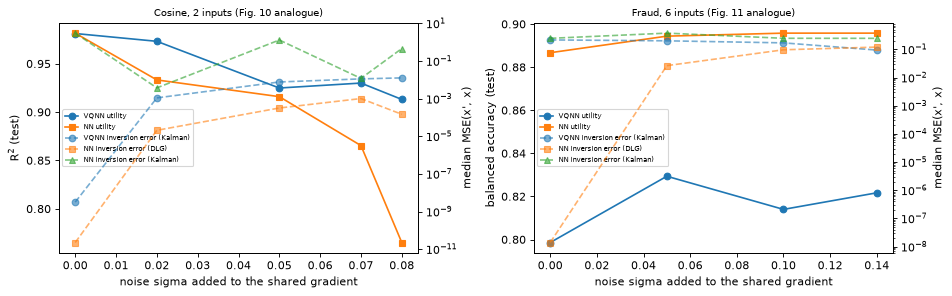

,dataset,sigma,VQNN_train,VQNN_test,NN_train,NN_test,VQNN_Kalman_mse,VQNN_success,NN_DLG_mse,NN_Kalman_mse
0,cos,0.00,0.9783,0.9812,0.9782,0.9816,0.0000,80.0,0.0000,3.0445
1,cos,0.02,0.9688,0.9731,0.9394,0.9332,0.0011,60.0,0.0000,0.0037
2,cos,0.05,0.9305,0.9249,0.8943,0.9159,0.0077,40.0,0.0003,1.3130
3,cos,0.07,0.9269,0.9300,0.8653,0.8653,0.0112,20.0,0.0010,0.0120
4,cos,0.08,0.9029,0.9131,0.7553,0.7651,0.0127,20.0,0.0001,0.4595


,dataset,sigma,VQNN_train,VQNN_test,NN_train,NN_test,VQNN_Kalman_mse,VQNN_success,NN_DLG_mse,NN_Kalman_mse
0,fraud,0.00,0.8915,0.7986,0.9556,0.8867,0.2157,0.0,0.0000,0.2457
1,fraud,0.05,0.9000,0.8294,0.9512,0.8944,0.2005,0.0,0.0264,0.3756
2,fraud,0.10,0.9085,0.8140,0.9490,0.8958,0.1696,0.0,0.0964,0.2464
3,fraud,0.14,0.9128,0.8217,0.9471,0.8958,0.0941,0.0,0.1201,0.2457


In [22]:
def dp_study(key, J, arch, nn_sizes, sigmas, n_att, seed=SEED):
    """For every noise level sigma: train a VQNN and a classical NN with noisy gradients (utility), then attack the noisy
    gradient shared by the trained model: Kalman attack on the VQNN, DLG and the Kalman attack on the NN."""
    d = DATA[(key, J)]
    tr, te = split_idx(len(d["y"]))
    hi = ANGLE_HI["zz" if arch == "ZZEfficient" else "rx"]
    pipe = AnglePipe(key, J, hi).fit(d["X"][tr], d["y"][tr])
    Atr, Ate, ytr, yte = pipe.transform(d["X"][tr]), pipe.transform(d["X"][te]), d["y"][tr], d["y"][te]
    out = []
    for sg in sigmas:
        t0 = time.time()
        m = make_model(arch, J)
        th = train_vqnn(m, Atr, ytr, epochs=DP_EPOCHS, lr=TRAIN_LR, seed=seed, noise_sigma=sg); m.set_theta(th)
        tg = make_targets(Atr, hi, 1, n_att, seed=seed + 5)
        rv = run_trials(m, tg, atk_params(arch, J), kalman=True, K=K_for(arch, J), g_noise=sg, noise_seed=seed)
        nn = TinyNN(nn_sizes)
        thn = train_nn(nn, Atr, ytr, epochs=NN_EPOCHS, lr=TRAIN_LR, seed=seed, noise_sigma=sg); nn.set_theta(thn)
        nrng = np.random.default_rng(seed + 11)
        dlg_m, kal_m = [], []
        for x, x0 in tg:
            g = nn.grad(x)[0] + sg * nrng.standard_normal(nn.M)
            best = None                                                   # DLG with 5 random restarts, keep the best gradient match
            for r in range(5):
                xs = np.random.default_rng(seed + 100 * r).uniform(0, hi, x.shape)
                xr, _ = dlg_attack(nn, g, x, xs, iters=10)
                gl = ((nn.grad(xr).sum(0) - g) ** 2).mean()
                if best is None or gl < best[0]: best = (gl, float(((np.clip(xr, 0, hi) - x) ** 2).mean()))   # the attacker knows the data range: project into it
            dlg_m.append(best[1])
            xk, _ = invert(nn, g, x, x0, K=100 if J == 6 else 200, N0=32, h=0.05, lr=30.0, thr=ATK_THR, kalman=True)
            kal_m.append(float(((np.clip(xk, 0, hi) - x) ** 2).mean()))
        out.append(dict(dataset=key, sigma=sg, VQNN_train=score(m.predict(Atr, th), ytr, d["task"]), VQNN_test=score(m.predict(Ate, th), yte, d["task"]),
                        NN_train=score(nn.predict(Atr, thn), ytr, d["task"]), NN_test=score(nn.predict(Ate, thn), yte, d["task"]),
                        VQNN_Kalman_mse=float(np.median([r["mse"] for r in rv])), VQNN_success=100 * np.mean([r["success"] for r in rv]),
                        NN_DLG_mse=float(np.median(dlg_m)), NN_Kalman_mse=float(np.median(kal_m))))
        print(f"{key} sigma={sg:.2f}: VQNN test {out[-1]['VQNN_test']:.3f} / NN test {out[-1]['NN_test']:.3f} | median MSE  VQNN-Kalman {out[-1]['VQNN_Kalman_mse']:.1e}  "
              f"NN-DLG {out[-1]['NN_DLG_mse']:.1e}  NN-Kalman {out[-1]['NN_Kalman_mse']:.1e}   [{time.time()-t0:.0f}s]", flush=True)
    return pd.DataFrame(out)

DP_COS = dp_study("cos", 2, "Complex", [2, 16, 16, 1], DP_SIG_COS, N_DP_ATTACKS)
DP_FRAUD = dp_study("fraud", 6, "ZZEfficient", [6, 2, 1], DP_SIG_FRAUD, N_DP_ATTACKS_FRAUD)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, df, ttl, ylab in [(axes[0], DP_COS, "Cosine, 2 inputs (Fig. 10 analogue)", "R$^2$ (test)"), (axes[1], DP_FRAUD, "Fraud, 6 inputs (Fig. 11 analogue)", "balanced accuracy (test)")]:
    ax.plot(df.sigma, df.VQNN_test, "o-", color="tab:blue", label="VQNN utility"); ax.plot(df.sigma, df.NN_test, "s-", color="tab:orange", label="NN utility")
    ax.set_xlabel("noise sigma added to the shared gradient"); ax.set_ylabel(ylab); ax.set_title(ttl, fontsize=9)
    a2 = ax.twinx()
    a2.plot(df.sigma, df.VQNN_Kalman_mse, "o--", color="tab:blue", alpha=0.6, label="VQNN inversion error (Kalman)")
    a2.plot(df.sigma, df.NN_DLG_mse, "s--", color="tab:orange", alpha=0.6, label="NN inversion error (DLG)")
    a2.plot(df.sigma, df.NN_Kalman_mse, "^--", color="tab:green", alpha=0.6, label="NN inversion error (Kalman)")
    a2.set_yscale("log"); a2.set_ylabel("median MSE(x', x)")
    h1, l1 = ax.get_legend_handles_labels(); h2, l2 = a2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, fontsize=6, loc="center left")
plt.tight_layout(); plt.show()
display(DP_COS.round(4)); display(DP_FRAUD.round(4))

## 8. The paper's numbers next to ours

Verdict rules: Table I scores are "reproduced" within 2 points; attack success rates (10 trials, standard error up to 16 points) within 20 points; the precision of successful attacks is "reproduced" when their mean MSE is below the paper's own success threshold 0.005 (the paper's means of 1e-4 to 1e-3 are
averages over successes of attacks stopped after 200-250 iterations, whereas our successful attacks usually go much further because the iteration budget is not capped by a stopping rule); the qualitative claims are judged from the numbers of the corresponding cell. "Not reached" and "exceeded" always carry the gap.

In [23]:
# ---- side-by-side comparison with the paper, one verdict per checkable claim ----
# Rules: Table I accuracies "reproduced" within 2 points, otherwise "not reached" / "exceeded" with the gap;
#        attack success rates (10 trials, binomial standard error ~15 points) "reproduced" within 20 points;
#        attack precision: the paper's criterion is MSE <= 0.005, so a mean MSE of the successful attacks below that is "reproduced".
def v_pts(nb, paper, tol):
    gap = nb - paper
    if abs(gap) <= tol: return "reproduced"
    return f"{'exceeded' if gap > 0 else 'not reached'} ({gap:+.1f})"

claims = []
for r in TABLE1_DF.itertuples():
    for part, nbv, pv in [("train", r.notebook_train, r.paper_train), ("test", r.notebook_test, r.paper_test)]:
        claims.append(dict(claim=f"Table I: {r.dataset} {r.model}, {r.qubits} qubits, {part} {r.metric}", paper=pv, notebook=nbv, verdict=v_pts(nbv, pv, 2)))
rows2 = TABLE2_DF.to_dict("records")
for r in rows2:
    for who, pk, nk, pm, nm in [("adaptive", "paper adaptive %", "notebook adaptive %", "paper adaptive MSE", "notebook adaptive MSE (successful)"),
                                ("Kalman", "paper Kalman %", "notebook Kalman %", "paper Kalman MSE", "notebook Kalman MSE (successful)")]:
        claims.append(dict(claim=f"Table II: {r['model']}, {who}, one-shot success %", paper=r[pk], notebook=round(r[nk], 1), verdict=v_pts(r[nk], r[pk], 20)))
        mse = r[nm]
        claims.append(dict(claim=f"Table II: {r['model']}, {who}, MSE of successful attacks", paper=r[pm], notebook=("none succeeded" if np.isnan(mse) else float(f"{mse:.1e}")),
                           verdict=("cannot be checked (no successful attack)" if np.isnan(mse) else ("reproduced (<= 0.005)" if mse <= SUCCESS_MSE else "not reached"))))
# qualitative claims
six = [r for r in rows2 if r["model"].startswith("VQNN 6")]
better = sum(r["notebook Kalman %"] >= r["notebook adaptive %"] for r in six)
claims.append(dict(claim="Kalman filter does not hurt / improves success on the three 6-dimensional rows", paper="improves in 3 of 3 (40->70, 50->70, 40->80)",
                   notebook=f"Kalman >= adaptive in {better} of {len(six)}", verdict="reproduced" if better == len(six) and any(r['notebook Kalman %'] > r['notebook adaptive %'] for r in six) else "not reached"))
claims.append(dict(claim="Fig. 8: more ansatz parameters -> more attack iterations", paper="longer convergence for 8, 12, 16, 20 parameters",
                   notebook=str(F8.mean_iterations.round(0).tolist()), verdict="reproduced" if F8.mean_iterations.dropna().is_monotonic_increasing and F8.mean_iterations.notna().sum() >= 3 else "not reached (not monotone)"))
a16, k16 = F9.set_index("attack").success_pct["adaptive N=16"], F9.set_index("attack").success_pct["Kalman N=16"]
claims.append(dict(claim="Fig. 9: with a small window (N=16) the plain attack fails but the Kalman attack succeeds", paper="plain N=16 fails, Kalman N=16 succeeds",
                   notebook=f"success {a16:.0f}% (plain) vs {k16:.0f}% (Kalman)", verdict="reproduced" if k16 > a16 else "not reached"))
nf = NOFILT.set_index("model"); c_nf, c_lb, c_f = nf.columns[1], nf.columns[2], nf.columns[3]
claims.append(dict(claim="Finite differences alone (no low-pass filter) are not enough on the rugged landscape", paper="FDM alone fails to reach the global minimum",
                   notebook="; ".join(f"{m.replace('VQNN ','')}: {r[c_nf]:.0f}% / {r[c_lb]:.0f}% (no filter) vs {r[c_f]:.0f}% (filter)" for m, r in nf.iterrows()),
                   verdict="reproduced" if (nf[c_f] > nf[c_nf]).any() or (nf[c_f] > nf[c_lb]).any() else "not reached"))
claims.append(dict(claim="Fig. 15: longer runs reach MSE ~1e-10", paper="down to 1e-10", notebook=f"best of 6 attacks, K=700: {min(r['mse'] for r in long):.1e}", verdict="reproduced" if min(r['mse'] for r in long) <= 1e-9 else "not reached"))
claims.append(dict(claim="Fig. 16: attack works with random initial weights", paper="converges to ~1e-10 for 4 different weight vectors", notebook=f"success % per weight vector: {rw}", verdict="reproduced" if min(rw) >= 60 else "not reached"))
sT = 100 * np.mean([r["success"] for r in resT])
claims.append(dict(claim="Fig. 17: attack also works on the gradient of a trained model (6 inputs, ZZEfficient)", paper="converges to ~1e-5 (3 attacks)", notebook=f"success {sT:.0f}% of {len(resT)}; best MSE {min(r['mse'] for r in resT):.1e}", verdict="reproduced" if sT >= 50 else "not reached"))
c8 = DP_COS.set_index("sigma").loc[0.08]; c0 = DP_COS.set_index("sigma").loc[0.0]
claims.append(dict(claim="Table III / Fig. 10: DLG recovers the data of the NN without noise", paper="MSE < 0.002 in 10 iterations (NN16x2)", notebook=f"median MSE {c0.NN_DLG_mse:.1e}", verdict="reproduced" if c0.NN_DLG_mse < 0.002 else "not reached"))
claims.append(dict(claim="Fig. 10: with noise 0.08 the VQNN is harder to invert than the NN", paper="VQNN more secure at equal noise",
                   notebook=f"median MSE VQNN {c8.VQNN_Kalman_mse:.1e} vs NN (DLG {c8.NN_DLG_mse:.1e}, Kalman {c8.NN_Kalman_mse:.1e}); utility {c8.VQNN_test:.2f} vs {c8.NN_test:.2f}",
                   verdict="reproduced" if c8.VQNN_Kalman_mse > max(c8.NN_DLG_mse, c8.NN_Kalman_mse) else "not reached"))
f10 = DP_FRAUD.set_index("sigma").loc[0.10]
claims.append(dict(claim="Fig. 11: at sigma = 0.1 the Fraud VQNN still has utility but a noticeable inversion error", paper="MSE ~0.013, R2 = 0.65", notebook=f"median MSE {f10.VQNN_Kalman_mse:.1e}, balanced accuracy {f10.VQNN_test:.2f}",
                   verdict="reproduced" if 0.3 * 0.013 <= f10.VQNN_Kalman_mse <= 3 * 0.013 else ("exceeded" if f10.VQNN_Kalman_mse > 3 * 0.013 else "not reached")))
COMPARE = pd.DataFrame(claims)
pd.set_option("display.max_colwidth", 140)
display(COMPARE.style.set_properties(subset=["claim", "notebook"], **{"text-align": "left"}))
print(COMPARE.verdict.str.split(" ").str[0].value_counts().to_string())

,claim,paper,notebook,verdict
0,"Table I: cos Simple, 2 qubits, train R2",99,97.900000,reproduced
1,"Table I: cos Simple, 2 qubits, test R2",96,97.700000,reproduced
2,"Table I: cos Simple, 6 qubits, train R2",98,94.300000,not reached (-3.7)
3,"Table I: cos Simple, 6 qubits, test R2",94,94.000000,reproduced
4,"Table I: cos Complex, 2 qubits, train R2",99,97.900000,reproduced
5,"Table I: cos Complex, 2 qubits, test R2",98,97.700000,reproduced
6,"Table I: cos Complex, 6 qubits, train R2",99,90.100000,not reached (-8.9)
7,"Table I: cos Complex, 6 qubits, test R2",95,88.800000,not reached (-6.2)
8,"Table I: mnist Simple, 2 qubits, train BalAcc",89,67.900000,not reached (-21.1)
9,"Table I: mnist Simple, 2 qubits, test BalAcc",80,67.200000,not reached (-12.8)


verdict
reproduced    30
not           17
exceeded      10
cannot         1


## Reading the paper critically

*The numbers quoted below are those of the full run (`FAST_MODE = False`) stored in this notebook; the FAST demo uses fewer trials and will differ by several points.*

**What the evidence supports.** With *exact* gradients of small RX-encoded VQNNs the shared gradient really does determine the private input: every successful attack in this notebook goes on to MSE $10^{-6}$ to $10^{-9}$ (Fig. 15 analogue), and the paths in the Fig. 5/7 analogue lie on one line, so a small gradient loss means a small input error.
The failures are attacks that stop in a local minimum with a gradient loss of $10^{-3}$ to $10^{-2}$, not "other inputs with the same gradient". For the three RX-encoded single-sample rows the adaptive attack succeeded in 50-90 % of 10 attacks, and batches of two and three samples (summed gradient, order of the samples unrecoverable) were separated in 90 % of the attacks for a sufficiently over-parameterised
model (a 6-layer 2-qubit model; in our tuning runs the 3-layer version failed far more often). The paper's qualitative message - *a quantum model's gradient is not a safe thing to share* - is supported for this threat model. In the noise study on the cosine data the VQNN also kept more accuracy than the classical network at equal noise while being harder to invert ($\sigma=0.08$: $R^2=0.91$, median MSE 1.3e-2 versus $R^2=0.77$, DLG MSE 1.5e-4), which agrees with the paper's Fig. 10.

**What we could not reproduce.** The comparison table gives a verdict for every claim; the pattern is:
* *The Kalman filter did not help.* In the paper it raises the success rate of the 6-dimensional rows (40 to 70 %, 50 to 70 %, 40 to 80 %); here it lowered it (50 to 30 %, 30 to 0 %, 70 to 50 %), and the "Fig. 9" and ablation cells show no benefit either. With the all-ones matrices that the paper states, the filter reduces to a gain that settles at 0.618 (a damped gradient step) plus a shrink of the random start towards 0 in the first iteration.
  The ablation (40 attacks per variant) shows that the five variants - adaptive filter, Kalman, Kalman started at $x'_0$, plain descent with learning rate x 0.62, plain descent from a start scaled by 2/3 - are all within 32-40 %, i.e. within binomial noise (standard error about 8 points). A Kalman filter with a sensible process noise ($Q\ll R$) is the natural next experiment (exercise 4).
* *The low-pass filter was not shown to be necessary.* The paper says finite differences alone fail because of the huge number of local minima. Here the window size, the step $h$ and the stall threshold had almost no influence on the success rate, and *plain central differences with window N = 1* succeeded as often as the adaptive filter on the same secrets and starting points (90/70/70 % versus 90/50/70 %), while L-BFGS-B on the same loss was worse (40/10/50 %).
  The 2-D landscape of the 2-qubit model (Fig. 4 analogue) has only a handful of local minima. Either the paper's circuits have a far more rugged landscape than ours, or the filter matters less than claimed; this notebook cannot tell which. The step size (learning rate) mattered much more than the filter and had to be re-tuned for every model size.
* *The 6-input ZZEfficient row* is the weakest result: 30 % for the adaptive attack, 0 % with Kalman, and 0 of 4 on the *trained* 6-input model (Fig. 17 analogue). The ZZFeatureMap puts $(\pi-x_i)(\pi-x_j)$ into its phases, so the gradient oscillates with a frequency of the order $2(\pi-x_j)$ per interaction partner; on the data range $[0,2\pi]$ the attack never converged and we had to shrink the range to $[0,1]$ and the feature map to one linear repetition.
  How the paper scaled its fraud data and which ZZFeatureMap it used decides whether the 6-input attack is easy or hopeless - the paper does not say. Because this attack fails even without noise, the fraud half of the noise study (Fig. 11) cannot show how noise changes the inversion error of the VQNN.
* *Fig. 8 and Fig. 9.* The mean number of iterations needed to reach MSE 1e-5 is not monotone in the number of ansatz parameters (it fell from 15 to 7-9 iterations), and the window size N = 16 / 32 / 64 and the Kalman filter changed the success rate of the 2-qubit ZZEfficient attack by at most the binomial noise (60-90 % with 10 attacks).
* *Table I.* Several of our VQNNs score lower than the paper's (the 6-qubit *Complex* cosine model at 89 % $R^2$ against 95 %, the 2-qubit MNIST models at about 67 % against 80 %), several fraud models score higher. MNIST digits, the cosine target for $J>1$, the fraud preprocessing and the optimiser are our choices, so deviations of this size in either direction say little about the paper.

**Threat model and realism.** (i) The attacker knows the architecture *and the weights* $\theta$ and sees the exact gradient of the model *output*; real federated learning shares the gradient of the *loss*, which contains the unknown factor $2(\hat y-y)$ (exercise 5). (ii) Gradients are noise-free expectation values; on hardware they are estimated from a finite number of shots, which acts like the Gaussian noise of the privacy study and degrades the attack (exercise 7).
(iii) Success is declared at $\mathrm{MSE}\le0.005$: on data scaled to $[0,2\pi]$ this is a very small angular error, but on $[0,1]$ data (the ZZ models here) it is 3 % of the error of a random guess and should be judged against the range. (iv) Everything is a statement about *models with at most 6 inputs*; the paper itself says that batches larger than 3 make the model "under-parameterised" and that larger circuits trade attackability against training problems (barren plateaus).
(v) Ten attacks per row give success rates with a standard error of up to 16 points: most rows agree with the paper within that noise, but rankings between rows or between attack variants are not reliable.

**Privacy versus accuracy (Table III, Figs. 10-11).** On the cosine data the picture of the paper appears: the VQNN loses less accuracy than the classical network at the same $\sigma$ and is harder to invert. This is a statement about two *specific* models whose gradients have different scales, so the same $\sigma$ is not the same signal-to-noise ratio (exercise 6), and our classical network
had to be trained for four times as many epochs as the VQNN (600 against 150) to reach the same noise-free $R^2$. On the fraud data the classical network (balanced accuracy 0.89-0.90) beats the VQNN (0.80-0.83) at every $\sigma$ in our setup, and DLG recovers its input exactly without noise, while our attack could not invert the VQNN at all.

**Bottom line.** The notebook reproduces the *existence* of the leak for small RX-encoded VQNNs with exact gradients and the paper's cosine-data privacy-accuracy observation; it quantifies how much of the paper's performance tables depends on unreported details; it does not support the specific claims about the Kalman filter and the necessity of the low-pass filter,
nor the 6-input ZZEfficient success rates.

## Exercises

1. **Window size.** Set `ATK_N0` to 4, 16, 64 and 256 and rerun the 6-qubit cosine row of Table II (a few seconds). Which window gives the best success rate? Explain with the frequency content of the gradient (trigonometric polynomial of degree one in each $x_j$) what the filter removes.
2. **Barren plateaus.** Increase the number of layers of `make_model("Complex", 6, layers=...)` to 6 and 10 and plot the typical size of $|g|$ and the success rate. Does a larger, "more over-parameterised" ansatz make the attack easier (more equations than unknowns) or harder (flatter landscape)?
3. **Which weights?** Table II attacks the untrained model with all weights 1. Attack models with weights drawn from $U(0,2\pi)$ (Fig. 16) and from a trained network (Fig. 17) for 6-qubit models and compare success rates. Is the attack easier right after initialisation or at the end of training?
4. **A Kalman ablation of your own.** The ablation shows that, with the paper's all-ones matrices, the Kalman filter is a damped step with a start pulled towards 0. Replace the all-ones $Q$ and $R$ by $Q=10^{-3}$, $R=1$ (`invert(..., Q=1e-3)`), so that the gain falls to zero as the filter becomes confident. What happens to the success rate and to the final MSE?
5. **Unknown labels.** The shared gradient of the MSE loss is $2(\hat y-y)\,\partial\hat y/\partial\theta$. Treat the scalar $c=2(\hat y-y)$ as one more unknown of the attacker ($g'=c'\,\partial\hat y(x')/\partial\theta$, optimised with the same loop on the vector $(x',c')$). How much does the success rate drop?
6. **Noise calibration.** In the noise study, compute for each $\sigma$ the signal-to-noise ratio $\lVert g\rVert/(\sigma\sqrt M)$ and plot the inversion error against it for the VQNN and the NN. Is "more private at the same noise" only a statement about the different gradient scales of the two models?
7. **Shots.** The paper assumes exact expectation values. Replace the exact gradient by one estimated from $S$ measurement shots per circuit (add $\mathcal N(0,\,\mathrm{Var}/S)$ noise to every $\hat y(\theta\pm\tfrac\pi2e_m)$) for $S=10^2,10^3,10^4$. How many shots does the *client* need before the attack stops working?